# BirdCLEF+ 2026: data and audio exploration

Standalone EDA using Kaggle tables, audio files, and standard scientific libraries.
**No installation or import of the project package.** Run all cells from top to bottom.

We examine dataset size and coverage, class imbalance, metadata quality, weak and temporal
labels, source differences, spectrograms, and species co-presence.
Audio examples are diagnostic candidates, not automatically verified clean or noisy recordings.

Schema reference: [organizer data description](https://www.kaggle.com/competitions/birdclef-2026/data).
All numerical findings below are computed from the attached dataset version.

In [2]:
import ast
import base64
import io
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import seaborn as sns
import soundfile as sf
from scipy import signal
from IPython.display import HTML, Markdown, display
from tqdm import tqdm

%matplotlib inline

ROOT = Path('/kaggle/input/competitions/birdclef-2026')
SEED = 42
N_FOCAL_HEADERS = 800       # random sample, not a full audio-file audit
N_SOUNDSCAPE_HEADERS = 200  # plus every labeled file
N_AUDIO_DIAGNOSTICS = 48    # decode only the first 12 seconds of these focal files
PREVIEW_SECONDS = 12
SAMPLE_RATE_EXPECTED = 32_000
WINDOW_SECONDS = 5
SOUNDSCAPE_SECONDS = 60
MAX_WORKERS = 4

if not ROOT.is_dir():
    raise FileNotFoundError(f'Attach competition data or change ROOT: {ROOT}')
sns.set_theme(style='whitegrid', context='notebook', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', 20)
PALETTE = dict(zip(['Aves', 'Amphibia', 'Insecta', 'Mammalia', 'Reptilia'], sns.color_palette('colorblind', 5)))

## 1. Available data

`train.csv` describes focal recordings with clip-level labels; `train_soundscapes_labels.csv`
describes labeled intervals. Visible sample-submission rows illustrate the format, not the full test set.
We do not recursively scan all of `/kaggle/input` or decode the entire audio dataset.

In [3]:
train = pd.read_csv(ROOT / 'train.csv', dtype={'primary_label': str})
taxonomy = pd.read_csv(ROOT / 'taxonomy.csv', dtype={'primary_label': str})
sample = pd.read_csv(ROOT / 'sample_submission.csv')
sc_raw = pd.read_csv(ROOT / 'train_soundscapes_labels.csv', dtype={'primary_label': str})
classes = sample.columns.drop('row_id').tolist()
class_set = set(classes)
tax = taxonomy.set_index('primary_label').reindex(classes)

sc_paths = sorted((ROOT / 'train_soundscapes').glob('*.ogg'))
test_paths = sorted((ROOT / 'test_soundscapes').glob('*.ogg'))
inventory = pd.DataFrame([
    ('Focal metadata rows', len(train)),
    ('Target classes', len(classes)),
    ('Taxonomy rows', len(taxonomy)),
    ('Train soundscape files', len(sc_paths)),
    ('Visible test files', len(test_paths)),
    ('Sample submission rows (placeholders)', len(sample)),
    ('Raw soundscape annotation rows', len(sc_raw)),
], columns=['item', 'count'])
display(inventory)
for name, frame in [('train.csv', train), ('taxonomy.csv', taxonomy), ('soundscape labels', sc_raw)]:
    display(Markdown(f'**{name}**: shape `{frame.shape}`'))
    display(frame.head(3))

,item,count
0,Focal metadata rows,35549
1,Target classes,234
2,Taxonomy rows,234
3,Train soundscape files,10658
4,Visible test files,0
5,Sample submission rows (placeholders),3
6,Raw soundscape annotation rows,1478


**train.csv**: shape `(35549, 15)`

,primary_label,secondary_labels,type,latitude,longitude,scientific_name,common_name,class_name,inat_taxon_id,author,license,rating,url,filename,collection
0,1161364,[],[],-22.7562,-46.8666,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1216197.mp3?1727581626,1161364/iNat1216197.ogg,iNat
1,1161364,[],[],-22.7558,-46.8700,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/1114648.mp3?1719714347,1161364/iNat1114648.ogg,iNat
2,1161364,[],[],-22.7547,-46.8728,Guyalna cuta,Guyalna cuta,Insecta,1161364,Lucas Barbosa,cc-by-nc,0.0,https://static.inaturalist.org/sounds/810195.mp3?1694395513,1161364/iNat810195.ogg,iNat


**taxonomy.csv**: shape `(234, 5)`

,primary_label,inat_taxon_id,scientific_name,common_name,class_name
0,1161364,1161364,Guyalna cuta,Guyalna cuta,Insecta
1,116570,116570,Caiman yacare,Southern Spectacled Caiman,Reptilia
2,1176823,1176823,Leptodactylus luctator,Wrestler Frog,Amphibia


**soundscape labels**: shape `(1478, 4)`

,filename,start,end,primary_label
0,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:00,00:00:05,22961;23158;24321;517063;65380
1,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:05,00:00:10,22961;23158;24321;517063;65380
2,BC2026_Train_0039_S22_20211231_201500.ogg,00:00:10,00:00:15,22961;23158;24321;517063;65380


## 2. Metadata: missing values, duplicates, and weak labels

`secondary_labels` contains string representations of lists, parsed with `ast.literal_eval`.
Secondary annotations may be incomplete. A zero below means not annotated, not confirmed
absence of a species. `rating=0` means the rating is unavailable, not that recording quality is poor.

In [4]:
bad_secondary = []
def parse_secondary(value):
    try:
        parsed = ast.literal_eval(value) if isinstance(value, str) else value
        if not isinstance(parsed, list) or any(not isinstance(x, str) for x in parsed):
            raise ValueError('expected list of strings')
        return sorted(set(parsed))
    except (ValueError, SyntaxError, TypeError):
        bad_secondary.append(str(value))
        return []  # continue EDA only; report the parsing issue separately

train = train.copy()
raw_train_columns = train.columns.tolist()
raw_duplicate_rows = int(train.duplicated().sum())
train['secondary_list'] = train.secondary_labels.map(parse_secondary)
train['labels'] = [sorted(set([primary, *secondary])) for primary, secondary in zip(train.primary_label, train.secondary_list)]
train['n_secondary'] = train.secondary_list.map(len)
train['n_labels'] = train.labels.map(len)
train['path'] = train.filename.map(lambda name: str(ROOT / 'train_audio' / name))
known_labels = set(train.labels.explode().dropna())
unknown_labels = sorted(known_labels - class_set)
primary_counts = train.primary_label.value_counts().reindex(classes, fill_value=0)
any_clip_counts = train.labels.explode().value_counts().reindex(classes, fill_value=0)

metadata_checks = pd.Series({
    'Exact metadata duplicates': raw_duplicate_rows,
    'Repeated filenames (extra rows)': int(train.filename.duplicated().sum()),
    'Repeated non-null source URLs (extra rows)': int(train.url.dropna().duplicated().sum()),
    'Unparseable secondary-label rows': len(bad_secondary),
    'Unknown label codes': len(unknown_labels),
    'Unknown or missing authors': int((train.author.isna() | train.author.eq('Unknown')).sum()),
    'Missing primary labels': int(train.primary_label.isna().sum()),
    'Missing coordinates': int(train[['latitude', 'longitude']].isna().any(axis=1).sum()),
    'Zero coordinates (inspect, not automatically invalid)': int(((train.latitude == 0) & (train.longitude == 0)).sum()),
    'Rating unavailable (0 or NaN)': int((train.rating.fillna(0) == 0).sum()),
    'Target classes with no primary clips': int((primary_counts == 0).sum()),
    'Target classes with no focal labels at all': int((any_clip_counts == 0).sum()),
})
display(metadata_checks.to_frame('count'))
display(train[raw_train_columns].isna().mean().sort_values(ascending=False).rename('missing_fraction').to_frame())
if unknown_labels or bad_secondary:
    display({'unknown_labels': unknown_labels, 'malformed_secondary_examples': bad_secondary[:5]})

,count
Exact metadata duplicates,0
Repeated filenames (extra rows),0
Repeated non-null source URLs (extra rows),0
Unparseable secondary-label rows,0
Unknown label codes,0
Unknown or missing authors,1253
Missing primary labels,0
Missing coordinates,0
"Zero coordinates (inspect, not automatically invalid)",0
Rating unavailable (0 or NaN),12849


,missing_fraction
primary_label,0.0
secondary_labels,0.0
type,0.0
latitude,0.0
longitude,0.0
scientific_name,0.0
common_name,0.0
class_name,0.0
inat_taxon_id,0.0
author,0.0


## 3. Class imbalance and coverage

Compare primary labels with all known focal labels. Keep classes with no focal data:
their only supervision may come from soundscapes. Recording counts do not measure the
amount of useful vocal activity, so we also inspect durations and audio examples.

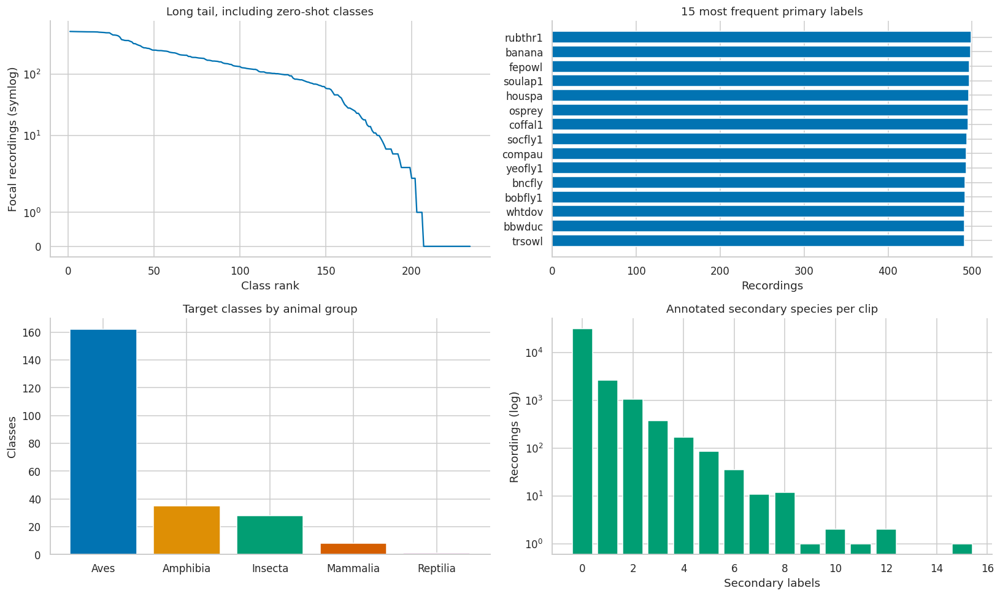

,common_name,class_name,primary_clips,any_clip_labels
primary_label,,,,
1491113,Guaraní leaf-litter frog,Amphibia,0,0
47158son03,Insect sonotype03,Insecta,0,0
47158son05,Insect sonotype05,Insecta,0,0
47158son04,Insect sonotype04,Insecta,0,0
47158son02,Insect sonotype02,Insecta,0,0
25073,Chiasmocleis mehelyi,Amphibia,0,0
47158son01,Insect sonotype01,Insecta,0,0
47158son14,Insect sonotype14,Insecta,0,0
47158son13,Insect sonotype13,Insecta,0,0


Top-10 primary classes contain **13.9%** of focal recordings; **18** classes have only 1–5 primary clips.

In [5]:
class_stats = tax[['common_name', 'class_name']].copy()
class_stats['primary_clips'] = primary_counts
class_stats['any_clip_labels'] = any_clip_counts
ranked = primary_counts.sort_values(ascending=False)
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
axes[0, 0].plot(np.arange(1, len(ranked)+1), ranked.values, color='#0072B2')
axes[0, 0].set(yscale='symlog', xlabel='Class rank', ylabel='Focal recordings (symlog)', title='Long tail, including zero-shot classes')
top = class_stats.sort_values('primary_clips').tail(15)
axes[0, 1].barh(top.index, top.primary_clips, color=[PALETTE.get(x, 'gray') for x in top.class_name])
axes[0, 1].set(title='15 most frequent primary labels', xlabel='Recordings')
group_counts = tax.class_name.fillna('Unknown').value_counts()
axes[1, 0].bar(group_counts.index, group_counts.values, color=[PALETTE.get(x, 'gray') for x in group_counts.index])
axes[1, 0].set(title='Target classes by animal group', ylabel='Classes')
secondary_hist = train.n_secondary.value_counts().sort_index()
axes[1, 1].bar(secondary_hist.index, secondary_hist.values, color='#009E73')
axes[1, 1].set(yscale='log', title='Annotated secondary species per clip', xlabel='Secondary labels', ylabel='Recordings (log)')
fig.tight_layout()
plt.show()
display(class_stats.query('primary_clips <= 5').sort_values('primary_clips'))
display(Markdown(f'Top-10 primary classes contain **{ranked.head(10).sum()/len(train):.1%}** of focal recordings; '
                 f'**{(primary_counts.between(1, 5)).sum()}** classes have only 1–5 primary clips.'))

## 4. Soundscape annotations: audit before aggregation

Remove **exact duplicate rows only**. Report different label sets for the same interval
separately. For EDA plots, take their species union instead of treating them as independent
observations. This is an explicit visualization rule, not a training-target policy.

Check interval lengths and boundaries. An unannotated window is not an empty window.

In [6]:
sc = sc_raw.drop_duplicates().copy()
sc['start_s'] = pd.to_timedelta(sc.start, errors='coerce').dt.total_seconds()
sc['end_s'] = pd.to_timedelta(sc.end, errors='coerce').dt.total_seconds()
sc['labels'] = sc.primary_label.fillna('').map(lambda value: sorted(set(x.strip() for x in value.split(';') if x.strip())))
sc['label_key'] = sc.labels.map(tuple)
interval_keys = ['filename', 'start_s', 'end_s']
conflicts = sc.groupby(interval_keys, dropna=False).label_key.nunique().loc[lambda x: x > 1]
bad_intervals = sc[
    sc[['start_s', 'end_s']].isna().any(axis=1)
    | (sc.start_s < 0) | (sc.end_s > SOUNDSCAPE_SECONDS)
    | ((sc.end_s - sc.start_s) != WINDOW_SECONDS)
    | ((sc.start_s % WINDOW_SECONDS) != 0)
]
sc_valid = sc.drop(index=bad_intervals.index)
windows = sc_valid.groupby(interval_keys, as_index=False).agg(
    labels=('labels', lambda series: sorted({label for labels in series for label in labels}))
)
windows['n_species'] = windows.labels.map(len)
sc_unknown = sorted(set(windows.labels.explode().dropna()) - class_set)
sc_counts = windows.labels.explode().value_counts().reindex(classes, fill_value=0)
class_stats['soundscape_windows'] = sc_counts
grid = pd.MultiIndex.from_product(
    [sorted(windows.filename.unique()), np.arange(0, SOUNDSCAPE_SECONDS, WINDOW_SECONDS)],
    names=['filename', 'start_s']
).to_frame(index=False).merge(windows, on=['filename', 'start_s'], how='left', indicator=True)
grid['annotated'] = grid['_merge'].eq('both')
annotation_checks = pd.Series({
    'Raw rows': len(sc_raw),
    'Exact duplicate rows removed': len(sc_raw) - len(sc),
    'Distinct annotation rows': len(sc),
    'Conflicting interval label sets': len(conflicts),
    'Invalid interval rows': len(bad_intervals),
    'Unique valid annotated windows': len(windows),
    'Labeled soundscape files': windows.filename.nunique(),
    'Unannotated 5s slots inside labeled files': int((~grid.annotated).sum()),
    'Unknown soundscape species codes': len(sc_unknown),
    'Annotated windows with 2+ species': int((windows.n_species >= 2).sum()),
    'Classes with no positive annotated windows': int((sc_counts == 0).sum()),
    'Classes with no negative annotated windows': int((sc_counts == len(windows)).sum()),
})
display(annotation_checks.to_frame('count'))
if len(conflicts):
    display(conflicts.rename('different_label_sets').to_frame().head(10))
if len(bad_intervals):
    display(bad_intervals.head(10))
display(Markdown('**Classes without any focal labels** — check their soundscape support:'))
display(class_stats.query('any_clip_labels == 0').sort_values('soundscape_windows', ascending=False))

,count
Raw rows,1478
Exact duplicate rows removed,739
Distinct annotation rows,739
Conflicting interval label sets,0
Invalid interval rows,0
Unique valid annotated windows,739
Labeled soundscape files,66
Unannotated 5s slots inside labeled files,53
Unknown soundscape species codes,0
Annotated windows with 2+ species,661


**Classes without any focal labels** — check their soundscape support:

,common_name,class_name,primary_clips,any_clip_labels,soundscape_windows
primary_label,,,,,
517063,Southern Orange-legged Leaf Frog,Amphibia,0,0,313
47158son25,Insect sonotype25,Insecta,0,0,84
1491113,Guaraní leaf-litter frog,Amphibia,0,0,79
47158son07,Insect sonotype07,Insecta,0,0,48
47158son17,Insect sonotype17,Insecta,0,0,43
47158son11,Insect sonotype11,Insecta,0,0,36
47158son13,Insect sonotype13,Insecta,0,0,36
47158son03,Insect sonotype03,Insecta,0,0,33
47158son10,Insect sonotype10,Insecta,0,0,33


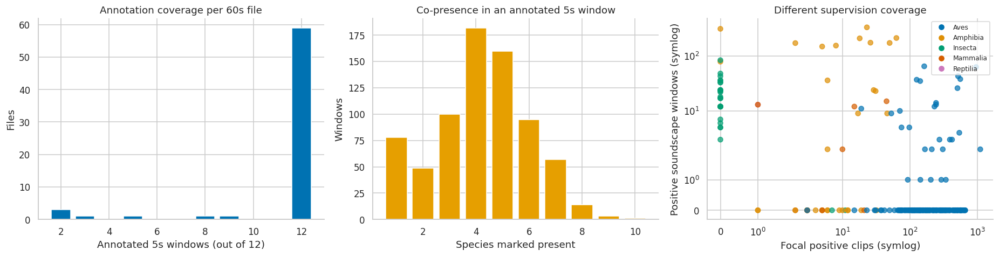

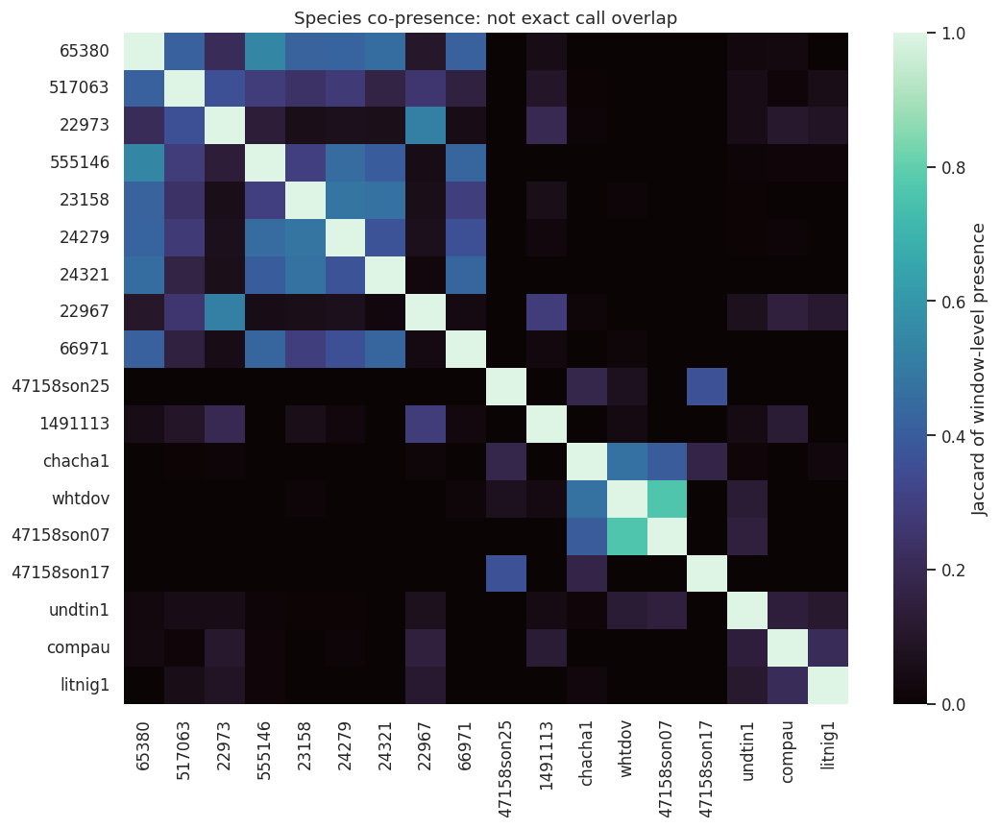

**3** class pairs have identical presence vectors across annotated windows (support ≥ 5). This may provide a shortcut for the model; matching annotations alone do not prove an error or exact acoustic synchrony.

,species_a,species_b,positive_windows
2,47158son22,47158son23,24
0,43435,47158son14,12
1,47158son15,47158son16,12


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
coverage = grid.groupby('filename').annotated.sum().value_counts().sort_index()
axes[0].bar(coverage.index, coverage.values, color='#0072B2')
axes[0].set(title='Annotation coverage per 60s file', xlabel='Annotated 5s windows (out of 12)', ylabel='Files')
counts = windows.n_species.value_counts().sort_index()
axes[1].bar(counts.index, counts.values, color='#E69F00')
axes[1].set(title='Co-presence in an annotated 5s window', xlabel='Species marked present', ylabel='Windows')
axes[2].scatter(class_stats.any_clip_labels, class_stats.soundscape_windows,
                c=[PALETTE.get(x, 'gray') for x in class_stats.class_name], alpha=0.7)
axes[2].set(xscale='symlog', yscale='symlog', xlabel='Focal positive clips (symlog)',
            ylabel='Positive soundscape windows (symlog)', title='Different supervision coverage')
axes[2].legend(handles=[Line2D([0], [0], marker='o', ls='', color=color, label=name) for name, color in PALETTE.items()], fontsize=8)
fig.tight_layout()
plt.show()

present = pd.DataFrame(0, index=windows.index, columns=classes, dtype=np.int32)
for index, labels in windows.labels.items():
    present.loc[index, [label for label in labels if label in class_set]] = 1
common = sc_counts.nlargest(18).index.tolist()
mat = present[common].to_numpy()
intersection = mat.T @ mat
support = mat.sum(axis=0)
union = support[:, None] + support[None, :] - intersection
jaccard = np.divide(intersection, union, out=np.zeros_like(intersection, dtype=float), where=union > 0)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(pd.DataFrame(jaccard, index=common, columns=common), vmin=0, vmax=1, cmap='mako', ax=ax,
            cbar_kws={'label': 'Jaccard of window-level presence'})
ax.set_title('Species co-presence: not exact call overlap')
fig.tight_layout()
plt.show()

# Identical presence vectors are a diagnostic signal, not proof of annotation errors.
all_present = present.to_numpy()
all_intersections = all_present.T @ all_present
all_support = all_present.sum(axis=0)
identical = (all_intersections == all_support[:, None]) & (all_intersections == all_support[None, :]) & (all_support[:, None] >= 5)
pair_indices = np.argwhere(np.triu(identical, k=1))
identical_pairs = pd.DataFrame([
    {'species_a': classes[a], 'species_b': classes[b], 'positive_windows': int(all_support[a])}
    for a, b in pair_indices
], columns=['species_a', 'species_b', 'positive_windows'])
display(Markdown(f'**{len(identical_pairs)}** class pairs have identical presence vectors across annotated windows (support ≥ 5). This may provide a shortcut for the model; matching annotations alone do not prove an error or exact acoustic synchrony.'))
display(identical_pairs.sort_values('positive_windows', ascending=False).head(12))


## 5. Sources, contributors, sites, and time

Rating availability depends on the collection: missing iNaturalist ratings do not imply
low quality. Extract soundscape site and UTC time from filenames. Compare all available
training soundscapes with the small labeled subset, whose distribution may be biased.

,files,labeled_files
site,,
S22,3383,40
S02,2505,0
S01,2341,0
S13,1873,2
S19,76,3
S18,54,2
S06,54,0
S07,52,0
S16,48,0


,recordings,authors,rating_unavailable,secondary_label_fraction
collection,,,,
XC,23043,1230,0.014885,0.189732
iNat,12506,2840,1.000000,0.000000


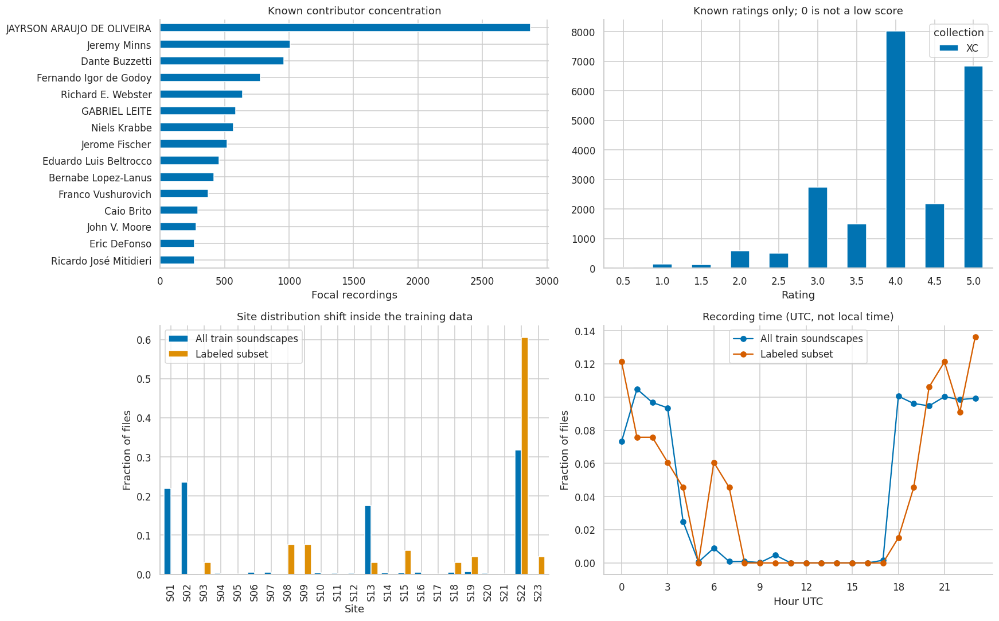

In [8]:
sc_inventory = pd.DataFrame({'filename': [p.name for p in sc_paths]})
parts = sc_inventory.filename.str.extract(r'_(?P<site>S\d+)_(?P<date>\d{8})_(?P<clock>\d{6})\.ogg$')
sc_inventory = pd.concat([sc_inventory, parts], axis=1)
sc_inventory['timestamp_utc'] = pd.to_datetime(sc_inventory.date + sc_inventory.clock, format='%Y%m%d%H%M%S', errors='coerce', utc=True)
sc_inventory['hour_utc'] = sc_inventory.timestamp_utc.dt.hour
sc_inventory['labeled'] = sc_inventory.filename.isin(windows.filename.unique())
display(pd.DataFrame({
    'files': sc_inventory.groupby('site').size(),
    'labeled_files': sc_inventory.loc[sc_inventory.labeled].groupby('site').size(),
}).fillna(0).astype(int).sort_values('files', ascending=False))
display(train.groupby('collection', dropna=False).agg(
    recordings=('filename', 'size'), authors=('author', lambda values: values[values.notna() & values.ne('Unknown')].nunique()),
    rating_unavailable=('rating', lambda values: values.fillna(0).eq(0).mean()),
    secondary_label_fraction=('n_secondary', lambda values: values.gt(0).mean())
))
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
train.loc[train.author.notna() & train.author.ne('Unknown'), 'author'].value_counts().head(15).iloc[::-1].plot.barh(ax=axes[0, 0], color='#0072B2')
axes[0, 0].set(title='Known contributor concentration', xlabel='Focal recordings', ylabel='')
ratings = train.assign(rating_known=train.rating.where(train.rating > 0))
rating_counts = pd.crosstab(ratings.rating_known, ratings.collection).reindex(np.arange(0.5, 5.1, 0.5), fill_value=0)
rating_counts.plot.bar(ax=axes[0, 1], rot=0)
axes[0, 1].set(title='Known ratings only; 0 is not a low score', xlabel='Rating')
site_share = pd.concat([
    sc_inventory.site.value_counts(normalize=True).rename('All train soundscapes'),
    sc_inventory.loc[sc_inventory.labeled, 'site'].value_counts(normalize=True).rename('Labeled subset')
], axis=1).fillna(0).sort_index()
site_share.plot.bar(ax=axes[1, 0], width=0.8)
axes[1, 0].set(title='Site distribution shift inside the training data', ylabel='Fraction of files', xlabel='Site')
for flag, label, color in [(False, 'All train soundscapes', '#0072B2'), (True, 'Labeled subset', '#D55E00')]:
    values = sc_inventory.loc[sc_inventory.labeled, 'hour_utc'] if flag else sc_inventory.hour_utc
    share = values.value_counts(normalize=True).reindex(range(24), fill_value=0)
    axes[1, 1].plot(share.index, share.values, marker='o', label=label, color=color)
axes[1, 1].set(title='Recording time (UTC, not local time)', xlabel='Hour UTC', ylabel='Fraction of files', xticks=range(0, 24, 3))
axes[1, 1].legend()
fig.tight_layout()
plt.show()

## 5a. Independent support: species, recordings, and sites

Positive windows from the same recording are correlated. A hundred positive windows from
two files at one site do not provide the same diversity as a hundred windows from many sites.
Count unique positive files and sites in addition to windows, using only valid, deduplicated
annotations. Missing annotation slots do not become negative examples.

The site heatmaps distinguish recording counts from within-site window prevalence. Prevalence
from a tiny site sample is uncertain; high prevalence alone is not evidence of generalization.

In [9]:
support_rows = windows[['filename', 'start_s', 'end_s', 'labels']].explode('labels').dropna(subset=['labels'])
support_rows = support_rows.merge(sc_inventory[['filename', 'site']], on='filename', how='left', validate='many_to_one')
if support_rows.site.isna().any():
    raise ValueError('Some annotated files have no parsed site: inspect their filenames.')
class_coverage = support_rows.groupby('labels').agg(
    positive_windows=('filename', 'size'),
    positive_files=('filename', 'nunique'),
    positive_sites=('site', 'nunique'),
).reindex(classes, fill_value=0).astype(int)
class_coverage = class_coverage.join(tax[['common_name', 'class_name']])
class_coverage['focal_positive_clips'] = any_clip_counts
observed_classes = class_coverage.index[class_coverage.positive_windows > 0].tolist()
coverage_summary = pd.Series({
    'All target classes': len(classes),
    'Classes observed in annotated soundscapes': len(observed_classes),
    'Classes absent from annotated soundscapes': int(class_coverage.positive_windows.eq(0).sum()),
    'Observed classes confined to one positive file': int(class_coverage.positive_files.eq(1).sum()),
    'Observed classes confined to one positive site': int(class_coverage.positive_sites.eq(1).sum()),
    'Observed classes supported by fewer than five files': int(class_coverage.positive_files.between(1, 4).sum()),
})
display(coverage_summary.to_frame('count'))
display(class_coverage[['positive_windows', 'positive_files', 'positive_sites']].describe())
display(Markdown('**Least geographically/recording-diverse observed classes:**'))
display(class_coverage.loc[observed_classes].sort_values(['positive_sites', 'positive_files', 'positive_windows']).head(20))
display(Markdown('**Classes without focal supervision:**'))
display(class_coverage.query('focal_positive_clips == 0').sort_values('positive_sites'))

,count
All target classes,234
Classes observed in annotated soundscapes,75
Classes absent from annotated soundscapes,159
Observed classes confined to one positive file,29
Observed classes confined to one positive site,50
Observed classes supported by fewer than five files,57


,positive_windows,positive_files,positive_sites
count,234.000000,234.000000,234.000000
mean,13.341880,1.581197,0.478632
std,43.399959,4.698168,0.855161
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,4.750000,1.000000,1.000000
max,333.000000,40.000000,5.000000


**Least geographically/recording-diverse observed classes:**

,positive_windows,positive_files,positive_sites,common_name,class_name,focal_positive_clips
labels,,,,,,
plcjay1,1,1,1,Plush-crested Jay,Aves,204
ruther1,1,1,1,Rufescent Tiger Heron,Aves,93
rutjac1,1,1,1,Rufous-tailed Jacamar,Aves,341
sibtan2,1,1,1,Silver-beaked Tanager,Aves,292
wfwduc1,1,1,1,White-faced Whistling Duck,Aves,143
67252,2,1,1,Milk Frog,Amphibia,6
74113,2,1,1,Highland,Mammalia,10
bunibi1,2,1,1,Buff-necked Ibis,Aves,211
grekis,2,1,1,Great Kiskadee,Aves,1105


**Classes without focal supervision:**

,positive_windows,positive_files,positive_sites,common_name,class_name,focal_positive_clips
labels,,,,,,
25073,12,1,1,Chiasmocleis mehelyi,Amphibia,0
47158son02,7,1,1,Insect sonotype02,Insecta,0
47158son06,18,2,1,Insect sonotype06,Insecta,0
47158son07,48,4,1,Insect sonotype07,Insecta,0
47158son12,5,1,1,Insect sonotype12,Insecta,0
47158son14,12,1,1,Insect sonotype14,Insecta,0
47158son09,6,1,1,Insect sonotype09,Insecta,0
47158son23,24,2,1,Insect sonotype23,Insecta,0
47158son22,24,2,1,Insect sonotype22,Insecta,0


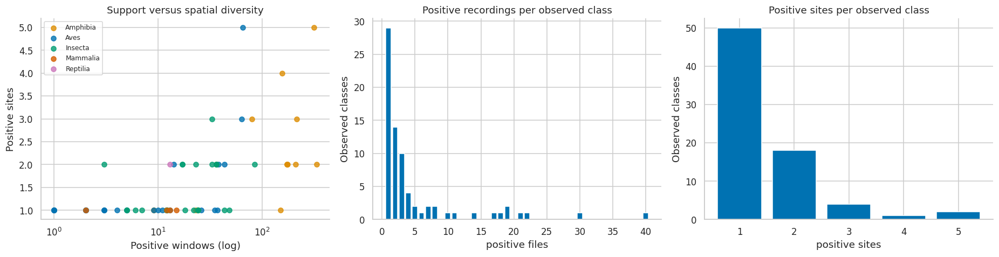

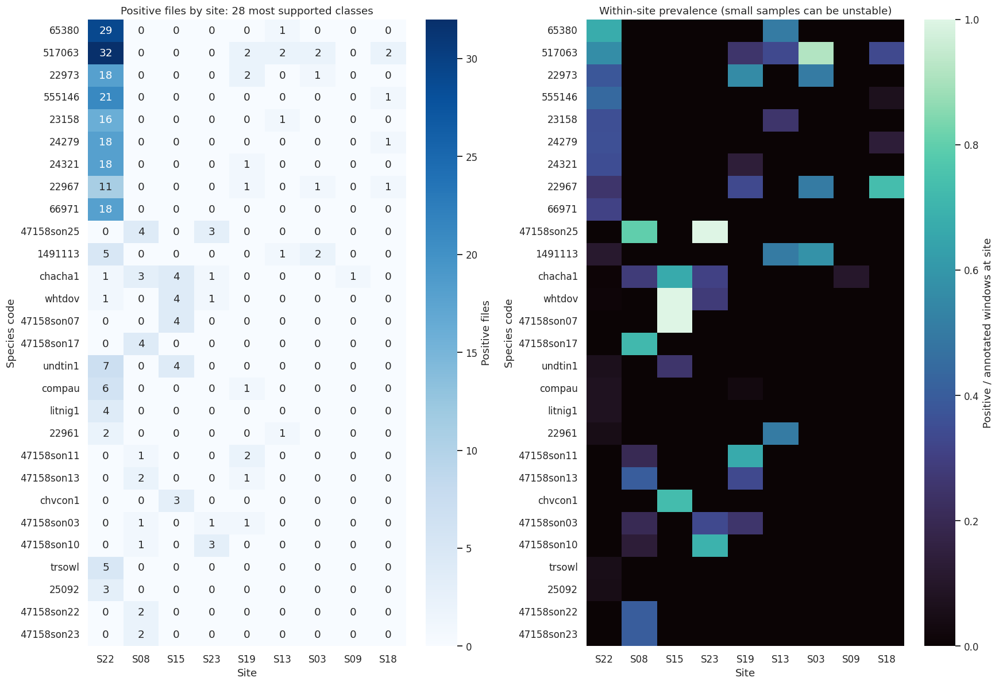

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
observed_support = class_coverage.loc[observed_classes]
for group, subset in observed_support.groupby('class_name'):
    axes[0].scatter(subset.positive_windows, subset.positive_sites, label=group,
                    color=PALETTE.get(group, 'gray'), alpha=0.8)
axes[0].set(xscale='log', xlabel='Positive windows (log)', ylabel='Positive sites', title='Support versus spatial diversity')
axes[0].legend(fontsize=8)
for ax, column, title in zip(axes[1:], ['positive_files', 'positive_sites'], ['Positive recordings per observed class', 'Positive sites per observed class']):
    histogram = observed_support[column].value_counts().sort_index()
    ax.bar(histogram.index, histogram.values, color='#0072B2')
    ax.set(xlabel=column.replace('_', ' '), ylabel='Observed classes', title=title)
fig.tight_layout()
plt.show()

site_windows = windows[['filename']].merge(sc_inventory[['filename', 'site']], on='filename', validate='many_to_one').site.value_counts()
site_order = site_windows.sort_values(ascending=False).index
shown_classes = class_coverage.nlargest(28, 'positive_windows').index
site_positive_files = pd.crosstab(support_rows.drop_duplicates(['labels', 'filename']).labels,
                                  support_rows.drop_duplicates(['labels', 'filename']).site)
site_positive_windows = pd.crosstab(support_rows.labels, support_rows.site)
file_heatmap = site_positive_files.reindex(index=shown_classes, columns=site_order, fill_value=0)
prevalence_heatmap = site_positive_windows.reindex(index=shown_classes, columns=site_order, fill_value=0).div(site_windows.reindex(site_order), axis=1)
fig, axes = plt.subplots(1, 2, figsize=(16, 11))
sns.heatmap(file_heatmap, annot=True, fmt='g', cmap='Blues', ax=axes[0], cbar_kws={'label': 'Positive files'})
sns.heatmap(prevalence_heatmap, vmin=0, vmax=1, cmap='mako', ax=axes[1], cbar_kws={'label': 'Positive / annotated windows at site'})
axes[0].set(title='Positive files by site: 28 most supported classes', xlabel='Site', ylabel='Species code')
axes[1].set(title='Within-site prevalence (small samples can be unstable)', xlabel='Site', ylabel='Species code')
fig.tight_layout()
plt.show()

## 5b. Validation feasibility: which classes would each fold evaluate?

Compare **5-fold GroupKFold by recording**, **5-fold GroupKFold by site**, and
**leave-one-site-out**. The folds use annotated soundscape windows only. Recordings/sites are
never shared across their corresponding train/validation partitions. These are diagnostic
partitions, not a final training protocol.

- No validation positives: the competition metric excludes the class.
- No validation negatives: AUC is undefined; the local scorer raises rather than silently dropping it.
- Both labels present: AUC is defined, but 1–4 positives or negatives still provide fragile support.
- A class can be absent from the training soundscapes. Report this separately from absence in
  **both** training soundscapes and all available focal labels. Focal labels remain weak supervision.

Without model predictions, actual AUC variance cannot be measured. Instead, inspect fold sizes,
support, scoring-class overlap, and site composition. Do not interpret class-set overlap as model
performance. Compare complete grouped OOF predictions on a consistent, explicitly reported class
universe; per-fold macro averages with changing class sets are not directly comparable.

Grouping here applies to soundscape rows. Adding all focal recordings does not guarantee spatial independence: exact focal-to-recorder site mapping is unavailable. Audit cross-source overlap before claiming strictly unseen-site performance.

In [31]:
from itertools import combinations
from sklearn.model_selection import GroupKFold, LeaveOneGroupOut

cv_meta = windows[['filename', 'start_s', 'end_s']].merge(
    sc_inventory[['filename', 'site']], on='filename', how='left', sort=False, validate='many_to_one'
)
if cv_meta.site.isna().any():
    raise ValueError('Every annotated recording needs a parsed site for site-level CV.')
if not cv_meta[['filename', 'start_s', 'end_s']].equals(windows[['filename', 'start_s', 'end_s']].reset_index(drop=True)):
    raise ValueError('Annotation order changed during metadata alignment.')
cv_targets = present.loc[windows.index, classes].to_numpy(dtype=np.int32)
has_focal_supervision = any_clip_counts.reindex(classes).to_numpy() > 0
globally_observed = cv_targets.sum(axis=0) > 0
all_labeled_sites = sorted(cv_meta.site.unique())
cv_protocols = [
    ('File GKF5', 'filename', GroupKFold(n_splits=5)),
    ('Site GKF5', 'site', GroupKFold(n_splits=5)),
    ('Leave-site-out', 'site', LeaveOneGroupOut()),
]
fold_rows, fold_class_rows, fold_masks, fold_states, fold_names = [], [], {}, [], []
for protocol, group_column, splitter in cv_protocols:
    groups = cv_meta[group_column]
    fold_masks[protocol] = []
    for fold, (train_idx, valid_idx) in enumerate(splitter.split(cv_targets, groups=groups), start=1):
        train_meta, valid_meta = cv_meta.iloc[train_idx], cv_meta.iloc[valid_idx]
        if set(train_meta[group_column]) & set(valid_meta[group_column]):
            raise ValueError('Grouping leakage detected.')
        train_positive = cv_targets[train_idx].sum(axis=0)
        valid_positive = cv_targets[valid_idx].sum(axis=0)
        valid_negative = len(valid_idx) - valid_positive
        eligible = (valid_positive > 0) & (valid_negative > 0)
        missing_negatives = (valid_positive > 0) & (valid_negative == 0)
        active_support = valid_positive[globally_observed]
        train_site_share = train_meta.site.value_counts(normalize=True).reindex(all_labeled_sites, fill_value=0)
        valid_site_share = valid_meta.site.value_counts(normalize=True).reindex(all_labeled_sites, fill_value=0)
        valid_sites = ', '.join(sorted(valid_meta.site.unique()))
        fold_name = f'{protocol} {fold}' if protocol != 'Leave-site-out' else f'LOSO {valid_sites}'
        fold_names.append(fold_name)
        fold_masks[protocol].append(eligible)
        fold_states.append(np.where(missing_negatives, 2, eligible.astype(int)))
        fold_rows.append({
            'protocol': protocol, 'fold': fold, 'validation_sites': valid_sites,
            'train_windows': len(train_idx), 'valid_windows': len(valid_idx),
            'valid_files': valid_meta.filename.nunique(),
            'val_positive_classes': int((valid_positive > 0).sum()),
            'val_auc_defined_classes': int(eligible.sum()),
            'val_no_positive_classes': int((valid_positive == 0).sum()),
            'val_no_negative_classes': int(missing_negatives.sum()),
            'val_fragile_auc_classes': int((eligible & ((valid_positive < 5) | (valid_negative < 5))).sum()),
            'val_unseen_in_sc_train': int(((valid_positive > 0) & (train_positive == 0)).sum()),
            'val_unseen_even_with_focal': int(((valid_positive > 0) & (train_positive == 0) & ~has_focal_supervision).sum()),
            'positive_support_min': int(active_support.min()),
            'positive_support_median': float(np.median(active_support)),
            'positive_support_max': int(active_support.max()),
            'site_total_variation': float(np.abs(train_site_share-valid_site_share).sum()/2),
        })
        for label, train_n, pos_n, neg_n, auc_defined in zip(classes, train_positive, valid_positive, valid_negative, eligible):
            fold_class_rows.append({'protocol': protocol, 'fold': fold, 'species': label,
                                   'train_positive_windows': int(train_n), 'valid_positive_windows': int(pos_n),
                                   'valid_negative_windows': int(neg_n), 'auc_defined': bool(auc_defined)})
fold_report = pd.DataFrame(fold_rows)
fold_class_support = pd.DataFrame(fold_class_rows)
summary_rows = []
for protocol, masks in fold_masks.items():
    overlap = []
    for left, right in combinations(masks, 2):
        union_count = (left | right).sum()
        overlap.append(float((left & right).sum()/union_count) if union_count else np.nan)
    rows = fold_report[fold_report.protocol == protocol]
    summary_rows.append({
        'protocol': protocol, 'folds': len(rows),
        'valid_windows_min': rows.valid_windows.min(), 'valid_windows_max': rows.valid_windows.max(),
        'auc_classes_min': rows.val_auc_defined_classes.min(), 'auc_classes_max': rows.val_auc_defined_classes.max(),
        'classes_auc_defined_in_every_fold': int(np.logical_and.reduce(masks).sum()),
        'folds_blocked_by_no_negatives': int(rows.val_no_negative_classes.gt(0).sum()),
        'mean_pairwise_class_jaccard': float(np.nanmean(overlap)),
        'max_val_classes_unseen_even_with_focal': rows.val_unseen_even_with_focal.max(),
    })
cv_summary = pd.DataFrame(summary_rows).set_index('protocol')
display(cv_summary.round(3))
display(fold_report)
display(Markdown('Positive-support min/median/max include **all globally observed soundscape classes**, including zeros in a particular validation fold. The fragile-support cutoff of five is diagnostic, not a statistical confidence guarantee. Site total variation is 1 for disjoint site splits by construction; it is not an AUC estimate.'))
display(Markdown('**Classes lacking validation negatives in any split:**'))
display(fold_class_support.query('valid_positive_windows > 0 and valid_negative_windows == 0'))

file_cv = cv_summary.loc['File GKF5']
site_cv = cv_summary.loc['Site GKF5']
loso_cv = cv_summary.loc['Leave-site-out']
display(Markdown(
    f"**Coverage findings:** {int(class_coverage.positive_files.eq(1).sum())} of {len(observed_classes)} observed classes occur in one positive file, "
    f"and {int(class_coverage.positive_sites.eq(1).sum())} in one positive site. File GKF5 evaluates "
    f"**{int(file_cv.auc_classes_min)}–{int(file_cv.auc_classes_max)}** classes per fold, with only "
    f"**{int(file_cv.classes_auc_defined_in_every_fold)}** eligible in every fold. Site GKF5 evaluates "
    f"**{int(site_cv.auc_classes_min)}–{int(site_cv.auc_classes_max)}**, with "
    f"**{int(site_cv.classes_auc_defined_in_every_fold)}** eligible in every fold. "
    f"Leave-one-site-out has **{int(loso_cv.folds_blocked_by_no_negatives)}** folds blocked by all-positive classes. "
    "Treat pooled file-grouped OOF evaluation as a candidate primary diagnostic and site-held-out folds as a separate stress test; "
    "do not interpret their macro scores as interchangeable or hide the unsupported classes."
))


,folds,valid_windows_min,valid_windows_max,auc_classes_min,auc_classes_max,classes_auc_defined_in_every_fold,folds_blocked_by_no_negatives,mean_pairwise_class_jaccard,max_val_classes_unseen_even_with_focal
protocol,,,,,,,,,
File GKF5,5,146,149,32,44,12,0,0.411,2
Site GKF5,5,60,477,18,29,0,0,0.124,9
Leave-site-out,9,15,477,4,29,0,2,0.067,9


,protocol,fold,validation_sites,train_windows,valid_windows,valid_files,val_positive_classes,val_auc_defined_classes,val_no_positive_classes,val_no_negative_classes,val_fragile_auc_classes,val_unseen_in_sc_train,val_unseen_even_with_focal,positive_support_min,positive_support_median,positive_support_max,site_total_variation
0,File GKF5,1,"S08, S09, S19, S22, S23",590,149,13,32,32,202,0,5,2,1,0,0.0,84,0.189603
1,File GKF5,2,"S08, S13, S15, S18, S22, S23",592,147,13,36,36,198,0,5,6,2,0,0.0,68,0.133446
2,File GKF5,3,"S08, S09, S13, S15, S22, S23",591,148,14,36,36,198,0,10,5,2,0,0.0,76,0.127041
3,File GKF5,4,"S03, S08, S09, S15, S19, S22",593,146,13,44,44,190,0,12,9,2,0,2.0,72,0.141445
4,File GKF5,5,"S03, S09, S15, S18, S19, S22",590,149,13,35,35,199,0,12,7,2,0,0.0,66,0.230076
5,Site GKF5,1,S22,262,477,40,29,29,205,0,7,14,0,0,0.0,321,1.000000
6,Site GKF5,2,"S08, S18",664,75,7,23,23,211,0,3,9,9,0,0.0,48,1.000000
7,Site GKF5,3,"S09, S15",672,67,9,18,18,216,0,8,13,1,0,0.0,48,1.000000
8,Site GKF5,4,"S03, S23",679,60,5,18,18,216,0,3,7,3,0,0.0,36,1.000000
9,Site GKF5,5,"S13, S19",679,60,5,22,22,212,0,2,7,4,0,0.0,24,1.000000


Positive-support min/median/max include **all globally observed soundscape classes**, including zeros in a particular validation fold. The fragile-support cutoff of five is diagnostic, not a statistical confidence guarantee. Site total variation is 1 for disjoint site splits by construction; it is not an AUC estimate.

**Classes lacking validation negatives in any split:**

,protocol,fold,species,train_positive_windows,valid_positive_windows,valid_negative_windows,auc_defined
3312,Leave-site-out,5,47158son07,0,48,0,False
3501,Leave-site-out,5,whtdov,15,48,0,False
4266,Leave-site-out,9,47158son25,48,36,0,False


**Coverage findings:** 29 of 75 observed classes occur in one positive file, and 50 in one positive site. File GKF5 evaluates **32–44** classes per fold, with only **12** eligible in every fold. Site GKF5 evaluates **18–29**, with **0** eligible in every fold. Leave-one-site-out has **2** folds blocked by all-positive classes. Treat pooled file-grouped OOF evaluation as a candidate primary diagnostic and site-held-out folds as a separate stress test; do not interpret their macro scores as interchangeable or hide the unsupported classes.

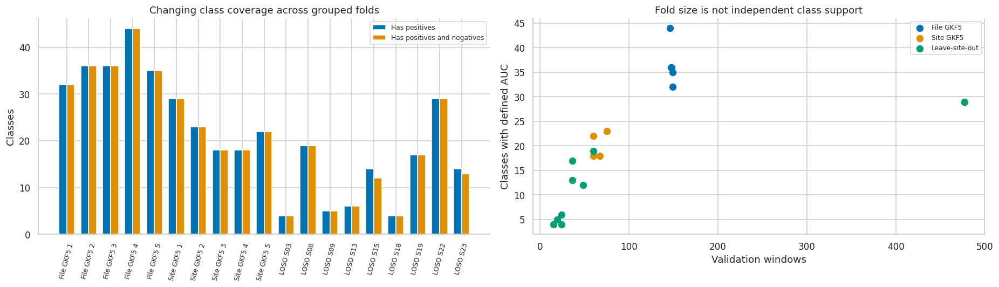

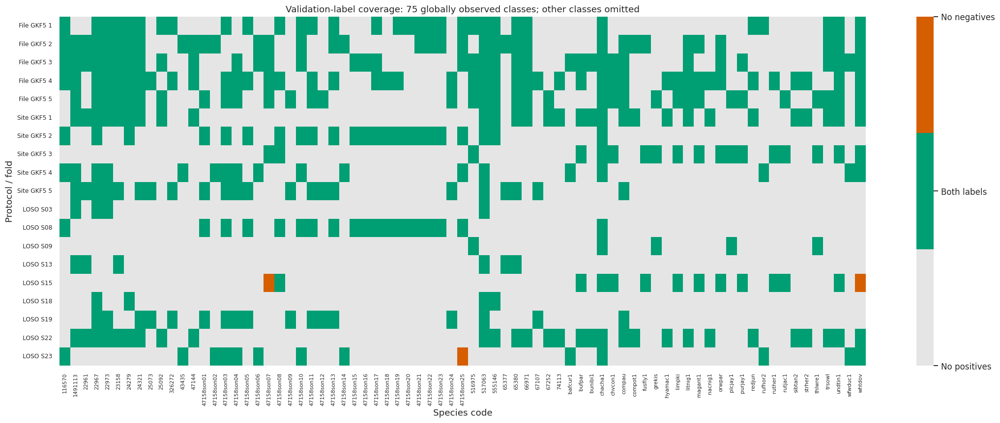

In [12]:
from matplotlib.colors import ListedColormap

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
x = np.arange(len(fold_report))
axes[0].bar(x-0.18, fold_report.val_positive_classes, width=0.36, label='Has positives')
axes[0].bar(x+0.18, fold_report.val_auc_defined_classes, width=0.36, label='Has positives and negatives')
axes[0].set(xticks=x, xticklabels=fold_names, ylabel='Classes', title='Changing class coverage across grouped folds')
axes[0].tick_params(axis='x', rotation=75, labelsize=8)
axes[0].legend(fontsize=8)
for protocol, rows in fold_report.groupby('protocol', sort=False):
    axes[1].scatter(rows.valid_windows, rows.val_auc_defined_classes, s=60, label=protocol)
axes[1].set(xlabel='Validation windows', ylabel='Classes with defined AUC', title='Fold size is not independent class support')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

state_table = pd.DataFrame(np.stack(fold_states)[:, globally_observed], index=fold_names,
                           columns=np.array(classes)[globally_observed])
fig, ax = plt.subplots(figsize=(20, 8))
sns.heatmap(state_table, cmap=ListedColormap(['#e5e5e5', '#009E73', '#D55E00']),
            vmin=0, vmax=2, xticklabels=True, yticklabels=True, ax=ax, cbar_kws={'ticks': [0, 1, 2]})
ax.collections[0].colorbar.set_ticklabels(['No positives', 'Both labels', 'No negatives'])
ax.set(title=f'Validation-label coverage: {int(globally_observed.sum())} globally observed classes; other classes omitted',
       xlabel='Species code', ylabel='Protocol / fold')
ax.tick_params(axis='x', rotation=90, labelsize=7)
ax.tick_params(axis='y', labelsize=8)
fig.tight_layout()
plt.show()

## 5c. Focal geography and source differences

These are coordinate plots, not a basemap or an area estimate. The organizer's
`recording_location.txt` supplies ranges of recorder coordinates: the red rectangle is their
bounding envelope, **not** the Pantanal boundary or exact recorder locations. A focal observation
inside this box is not proof of overlap with a specific recording site. Test-site coordinates are
not available here, so no exact focal-to-test distance or geographic prior is computed.

Invalid/missing coordinate rows: **0**. Organizer recorder ranges: latitude **-21.6 to -16.5**, longitude **-57.6 to -55.9**.

,recordings,min_latitude,max_latitude,min_longitude,max_longitude,inside_recorder_bbox_fraction
collection,,,,,,
XC,23043,-54.8378,69.5780,-159.6556,175.3239,0.0321
iNat,12506,-54.8574,64.8635,-159.5029,174.8237,0.0086


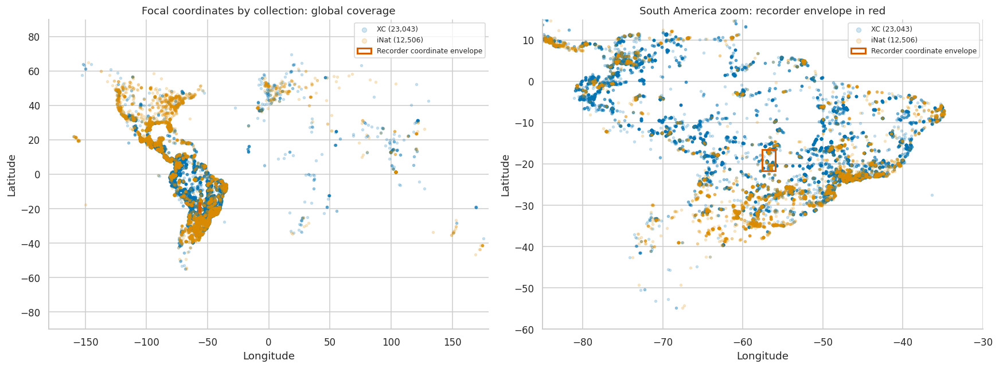

In [13]:
import re
from matplotlib.patches import Rectangle

location_text = (ROOT / 'recording_location.txt').read_text()
lat_match = re.search(r'Latitude:\s*(-?[0-9.]+)\s+to\s+(-?[0-9.]+)', location_text)
lon_match = re.search(r'Longitude:\s*(-?[0-9.]+)\s+to\s+(-?[0-9.]+)', location_text)
if not lat_match or not lon_match:
    raise ValueError('Recorder coordinate ranges are absent; inspect recording_location.txt.')
lat_low, lat_high = sorted(map(float, lat_match.groups()))
lon_low, lon_high = sorted(map(float, lon_match.groups()))
valid_coordinates = train.latitude.between(-90, 90) & train.longitude.between(-180, 180)
geo = train.loc[valid_coordinates].copy()
geo['inside_recorder_bbox'] = geo.latitude.between(lat_low, lat_high) & geo.longitude.between(lon_low, lon_high)
geo_summary = geo.groupby('collection').agg(
    recordings=('filename', 'size'), min_latitude=('latitude', 'min'), max_latitude=('latitude', 'max'),
    min_longitude=('longitude', 'min'), max_longitude=('longitude', 'max'),
    inside_recorder_bbox_fraction=('inside_recorder_bbox', 'mean'),
)
display(Markdown(f'Invalid/missing coordinate rows: **{int((~valid_coordinates).sum())}**. Organizer recorder ranges: latitude **{lat_low} to {lat_high}**, longitude **{lon_low} to {lon_high}**.'))
display(geo_summary.round(4))
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for collection, subset in geo.groupby('collection'):
    for ax in axes:
        ax.scatter(subset.longitude, subset.latitude, s=7, alpha=0.18, label=f'{collection} ({len(subset):,})', rasterized=True)
for ax in axes:
    ax.add_patch(Rectangle((lon_low, lat_low), lon_high-lon_low, lat_high-lat_low,
                          fill=False, edgecolor='#D55E00', lw=2, label='Recorder coordinate envelope'))
    ax.set(xlabel='Longitude', ylabel='Latitude')
    ax.legend(fontsize=8, markerscale=2)
axes[0].set(title='Focal coordinates by collection: global coverage', xlim=(-180, 180), ylim=(-90, 90))
axes[1].set(title='South America zoom: recorder envelope in red', xlim=(-85, -30), ylim=(-60, 15))
fig.tight_layout()
plt.show()

## 6. Audio properties: a sampled header audit

Read **headers**, not full signals: random focal recordings, random soundscapes,
and all labeled soundscapes. Check duration, sample rate, channel count, and read errors
without decoding all 35,000 recordings. Sampling uses a fixed seed.
Focal durations and error rates describe this sample only; full-dataset integrity is not established.

In [14]:
focal_sample = train.sample(min(N_FOCAL_HEADERS, len(train)), random_state=SEED)
random_sc = sc_inventory.sample(min(N_SOUNDSCAPE_HEADERS, len(sc_inventory)), random_state=SEED).filename.tolist()
header_jobs = [('focal', str(ROOT / 'train_audio' / filename), filename) for filename in focal_sample.filename]
header_jobs += [('soundscape', str(ROOT / 'train_soundscapes' / filename), filename)
                for filename in sorted(set(random_sc) | set(windows.filename))]

def read_header(job):
    source, path, filename = job
    row = {'source': source, 'filename': filename, 'path': path}
    try:
        info = sf.info(path)
        row.update(duration_s=info.duration, sample_rate=info.samplerate, channels=info.channels,
                   frames=info.frames, subtype=info.subtype, error=None)
    except (OSError, RuntimeError) as exc:
        row['error'] = f'{type(exc).__name__}: {exc}'
    return row

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    headers = pd.DataFrame(list(tqdm(pool.map(read_header, header_jobs), total=len(header_jobs), desc='Audio headers', mininterval=2, ascii=True)))
ok_headers = headers[headers.error.isna()].copy()
header_failures = headers[headers.error.notna()]
display(ok_headers.groupby('source').duration_s.describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(2))
display(ok_headers.groupby(['source', 'sample_rate', 'channels']).size().rename('files').to_frame())
display(header_failures if len(header_failures) else pd.DataFrame({'header_errors': [0]}))
labeled_headers = ok_headers[(ok_headers.source == 'soundscape') & ok_headers.filename.isin(windows.filename)]
display(Markdown(f'Focal files checked: **{(headers.source == "focal").sum()}**; '
                 f'soundscapes checked: **{(headers.source == "soundscape").sum()}**; '
                 f'labeled soundscapes not 60s: **{(~np.isclose(labeled_headers.duration_s, 60)).sum()}**.'))

display(Markdown('**Shortest focal files in the sample** — inspect padding needs and useful signal content:'))
display(ok_headers.query('source == "focal"').nsmallest(5, 'duration_s')[['filename', 'duration_s', 'sample_rate']])



Audio headers: 100%|##########| 1064/1064 [00:08<00:00, 118.36it/s]


,count,mean,std,min,10%,50%,90%,99%,max
source,,,,,,,,,
focal,800.0,33.84,55.5,0.04,5.18,20.14,68.68,260.94,859.87
soundscape,264.0,60.00,0.0,60.00,60.00,60.00,60.00,60.00,60.00


,,,files
source,sample_rate,channels,
focal,32000,1,800
soundscape,32000,1,264


,header_errors
0,0


Focal files checked: **800**; soundscapes checked: **264**; labeled soundscapes not 60s: **0**.

**Shortest focal files in the sample** — inspect padding needs and useful signal content:

,filename,duration_s,sample_rate
393,greyel/iNat1375792.ogg,0.0360,32000
631,whnjay1/iNat1404548.ogg,0.0480,32000
178,bobfly1/iNat1691483.ogg,0.1045,32000
493,osprey/iNat226664.ogg,0.1045,32000
529,coffal1/iNat1710475.ogg,0.1045,32000


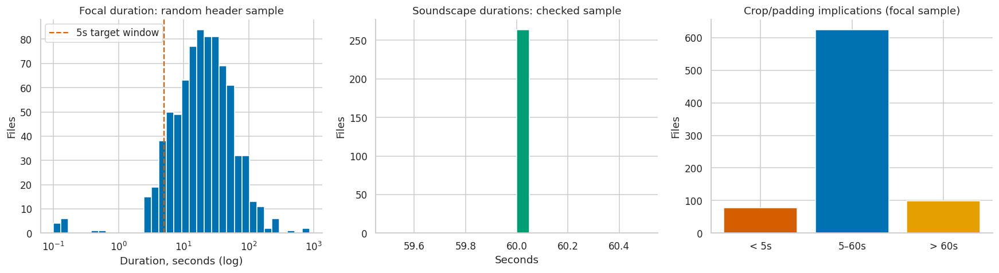

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
focal_durations = ok_headers.loc[ok_headers.source == 'focal', 'duration_s']
axes[0].hist(focal_durations, bins=np.geomspace(max(focal_durations.min(), 0.1), focal_durations.max()+0.01, 35), color='#0072B2')
axes[0].axvline(5, color='#D55E00', ls='--', label='5s target window')
axes[0].set(xscale='log', title='Focal duration: random header sample', xlabel='Duration, seconds (log)', ylabel='Files')
axes[0].legend()
sc_durations = ok_headers.loc[ok_headers.source == 'soundscape', 'duration_s']
axes[1].hist(sc_durations, bins=20, color='#009E73')
axes[1].set(title='Soundscape durations: checked sample', xlabel='Seconds', ylabel='Files')
short = pd.Series({'< 5s': int((focal_durations < 5).sum()), '5–60s': int(focal_durations.between(5, 60).sum()), '> 60s': int((focal_durations > 60).sum())})
axes[2].bar(short.index, short.values, color=['#D55E00', '#0072B2', '#E69F00'])
axes[2].set(title='Crop/padding implications (focal sample)', ylabel='Files')
fig.tight_layout()
plt.show()

## 7. Signal diagnostics and examples of different difficulty

Measure the first 12 seconds of a small random subset: RMS, peak, the fraction of very quiet
samples, and spectral flatness. These are **signal diagnostics**, not SNR measurements or
annotation-quality scores. A leading crop may miss the target vocalization. Stereo is averaged
to mono for visualization; source files are unchanged.

STFT spectrograms share a power color scale relative to amplitude 1 (`dB re 1`), without
normalizing each image separately. Audio previews contain the same excerpts, encoded as OGG
for compactness. Playback is never amplified. If the decoded peak exceeds 1, only the playback
signal is attenuated, with an explicit notice. Waveform amplitude axes are scaled individually
for readability; the spectrogram color scale remains shared.

Decoded OGG peaks can exceed 1 because of codec behavior; this does not prove clipping in
the source recording. A high `near_fullscale_fraction` warrants listening and inspection,
rather than automatic removal.

The STFT window is reduced for the extremely short example, so its frequency resolution
is lower than that of ordinary 12-second excerpts.

In [16]:
def load_excerpt(path, seconds=PREVIEW_SECONDS):
    with sf.SoundFile(str(path)) as audio:
        sample_rate = audio.samplerate
        data = audio.read(frames=int(seconds * sample_rate), dtype='float32', always_2d=True)
    if not len(data):
        raise ValueError(f'Empty recording: {Path(path).name}')
    mono = data.mean(axis=1)
    return mono, sample_rate

def spectrogram_db(audio, sample_rate):
    n_fft = min(1024, len(audio), max(16, len(audio)//4))
    frequencies, times, stft = signal.stft(audio, fs=sample_rate, nperseg=n_fft,
                                          noverlap=int(n_fft * 0.75), boundary=None, padded=False)
    return frequencies, times, 10 * np.log10(np.maximum(np.abs(stft)**2, 1e-12))

def audio_preview_html(audio, sample_rate):
    buffer = io.BytesIO()
    peak = float(np.max(np.abs(audio)))
    gain = min(1.0, 0.9/peak) if peak > 1 else 1.0
    sf.write(buffer, audio*gain, sample_rate, format='OGG', subtype='VORBIS')
    notice = ''
    if gain < 1:
        notice = f'<p>Playback is attenuated by {-20*np.log10(gain):.1f} dB: decoded peak={peak:.3f} &gt; 1. Plots and metrics use the original signal.</p>'
    encoded = base64.b64encode(buffer.getvalue()).decode('ascii')
    return notice + f'<audio controls preload="none" src="data:audio/ogg;base64,{encoded}"></audio>'

def embedded_audio(audio, sample_rate):
    display(HTML(audio_preview_html(audio, sample_rate)))

def signal_diagnostics(row):
    result = {'filename': row.filename}
    try:
        audio, sample_rate = load_excerpt(row.path)
        rms = np.sqrt(np.mean(audio.astype(np.float64)**2))
        peak = np.max(np.abs(audio))
        frequencies, density = signal.welch(audio, fs=sample_rate, nperseg=min(1024, len(audio)))
        density = np.maximum(density[frequencies >= 250], 1e-20)
        flatness = np.exp(np.mean(np.log(density))) / np.mean(density)
        result.update(rms_db=20*np.log10(max(rms, 1e-12)), peak=float(peak),
                      crest_db=20*np.log10(max(peak, 1e-12)/max(rms, 1e-12)),
                      quiet_fraction=float((np.abs(audio) < 1e-4).mean()),
                      near_fullscale_fraction=float((np.abs(audio) >= 0.999).mean()),
                      spectral_flatness=float(flatness), error=None)
    except (OSError, RuntimeError, ValueError) as exc:
        result['error'] = f'{type(exc).__name__}: {exc}'
    return result

def show_focal(filename, reason):
    record = train.loc[train.filename == filename].iloc[0]
    audio, sample_rate = load_excerpt(record.path)
    f, t, db = spectrogram_db(audio, sample_rate)
    fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True, gridspec_kw={'height_ratios': [1, 2]})
    axes[0].plot(np.arange(len(audio))/sample_rate, audio, lw=0.5, color='#0072B2')
    peak = max(float(np.max(np.abs(audio))), 1e-5)
    axes[0].set(ylim=(-1.05*peak, 1.05*peak), ylabel='Amplitude', title=f'{reason} | {record.common_name} | rating={record.rating:g}')
    image = axes[1].pcolormesh(t, f/1000, db, shading='auto', cmap='magma', vmin=-90, vmax=-20, rasterized=True)
    axes[1].set(xlabel='Time, seconds', ylabel='Frequency, kHz', ylim=(0, min(16, sample_rate/2000)))
    fig.colorbar(image, ax=axes, pad=0.01, label='STFT power, dB re 1')
    fig.suptitle(str(record.filename), fontsize=10, y=1.01)
    plt.show()
    display(Markdown(f'**Selection:** {reason}. **Group:** {record.class_name}. '
                     f'**Clip-level labels:** `{", ".join(record.labels)}`. '
                     f'Showing the first **{len(audio)/sample_rate:.1f} s**; not all clip-level labels necessarily occur in this excerpt.'))
    embedded_audio(audio, sample_rate)


Short waveform diagnostics: 100%|##########| 48/48 [00:06<00:00,  7.02it/s]


,rms_db,peak,crest_db,quiet_fraction,near_fullscale_fraction,spectral_flatness
count,48.000,48.000,48.000,48.000,48.000,48.000
mean,-31.480,0.447,21.496,0.027,0.002,0.049
std,11.099,0.318,7.015,0.034,0.014,0.094
min,-64.708,0.007,6.478,0.001,0.000,0.000
25%,-37.160,0.222,16.795,0.008,0.000,0.003
50%,-30.091,0.327,21.148,0.016,0.000,0.014
75%,-25.345,0.627,24.708,0.027,0.000,0.049
max,-4.077,1.319,39.933,0.150,0.098,0.514


,filename,error


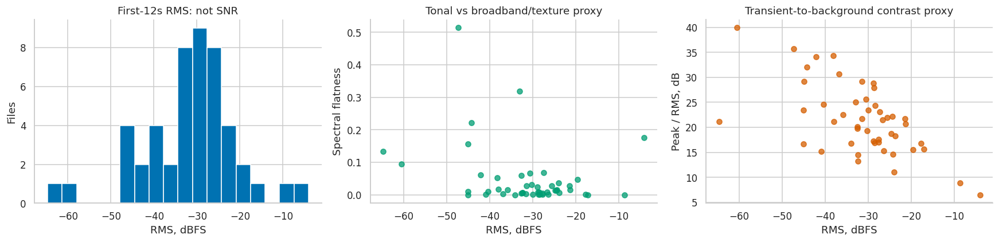

In [17]:
audit_inputs = ok_headers.query('source == "focal"').sample(
    min(N_AUDIO_DIAGNOSTICS, (ok_headers.source == 'focal').sum()), random_state=SEED
)
with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
    diagnostics = pd.DataFrame(list(tqdm(pool.map(signal_diagnostics, audit_inputs.itertuples(index=False)),
                                        total=len(audit_inputs), desc='Short waveform diagnostics', mininterval=2, ascii=True)))
display(diagnostics.describe().round(3))
display(diagnostics.loc[diagnostics.error.notna(), ['filename', 'error']])
signal_ok = diagnostics[diagnostics.error.isna()]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].hist(signal_ok.rms_db, bins=18, color='#0072B2')
axes[0].set(title='First-12s RMS: not SNR', xlabel='RMS, dBFS', ylabel='Files')
axes[1].scatter(signal_ok.rms_db, signal_ok.spectral_flatness, alpha=0.75, color='#009E73')
axes[1].set(title='Tonal vs broadband/texture proxy', xlabel='RMS, dBFS', ylabel='Spectral flatness')
axes[2].scatter(signal_ok.rms_db, signal_ok.crest_db, alpha=0.75, color='#D55E00')
axes[2].set(title='Transient-to-background contrast proxy', xlabel='RMS, dBFS', ylabel='Peak / RMS, dB')
fig.tight_layout()
plt.show()

def choose_example(mask, order_by, ascending=False):
    candidates = train.loc[mask].sort_values(order_by, ascending=ascending, kind='stable')
    for record in candidates.head(200).itertuples():
        if Path(record.path).is_file():
            return record.filename
    raise ValueError('No readable candidate in this category')

example_high = choose_example((train.class_name == 'Aves') & (train.n_secondary == 0) & (train.rating >= 4.5), 'rating')
example_multi = choose_example(train.n_secondary >= 2, 'n_secondary')
example_low = choose_example((train.rating > 0) & (train.rating <= 2.5), 'rating', ascending=True)
example_texture = choose_example(train.class_name == 'Insecta', 'rating')

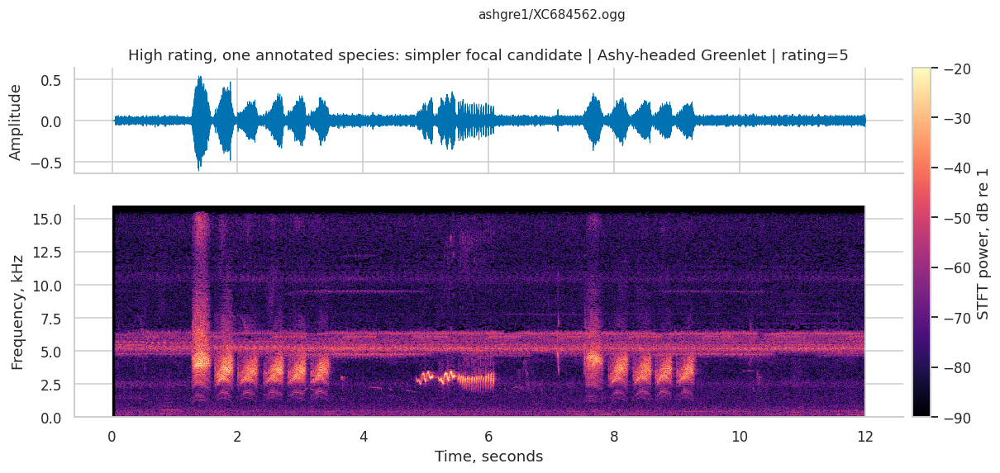

**Selection:** High rating, one annotated species: simpler focal candidate. **Group:** Aves. **Clip-level labels:** `ashgre1`. Showing the first **12.0 s**; not all clip-level labels necessarily occur in this excerpt.

In [18]:
show_focal(example_high, 'High rating, one annotated species: simpler focal candidate')

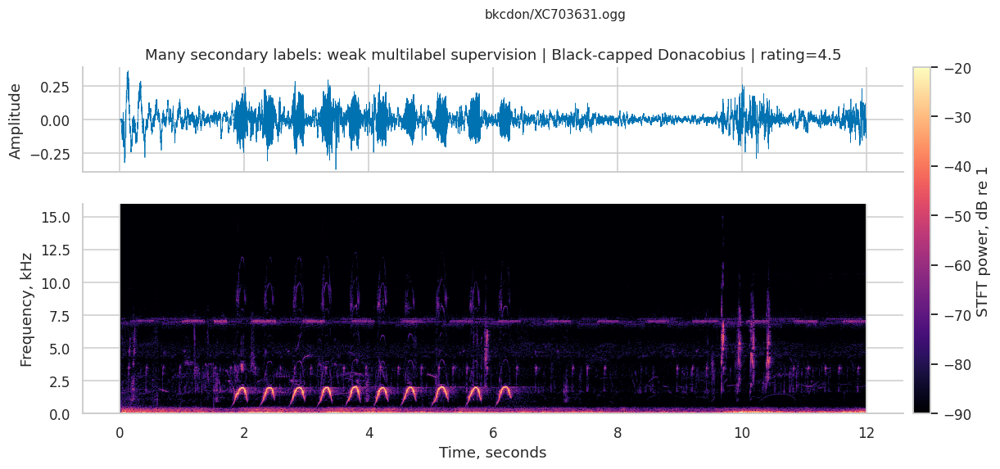

**Selection:** Many secondary labels: weak multilabel supervision. **Group:** Aves. **Clip-level labels:** `astcra1, baymac, bkcdon, chobla1, grasal3, grekis, pluibi1, rufhor2, smbani, sobcac1, soulap1, souscr1, strcuc1, watjac1, wfwduc1, whtdov`. Showing the first **12.0 s**; not all clip-level labels necessarily occur in this excerpt.

In [19]:
show_focal(example_multi, 'Many secondary labels: weak multilabel supervision')

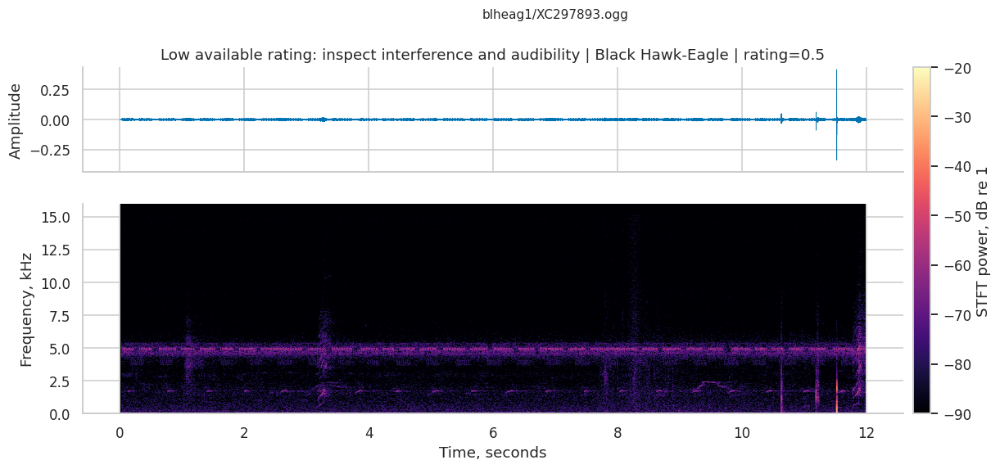

**Selection:** Low available rating: inspect interference and audibility. **Group:** Aves. **Clip-level labels:** `blheag1, fepowl`. Showing the first **12.0 s**; not all clip-level labels necessarily occur in this excerpt.

In [20]:
show_focal(example_low, 'Low available rating: inspect interference and audibility')

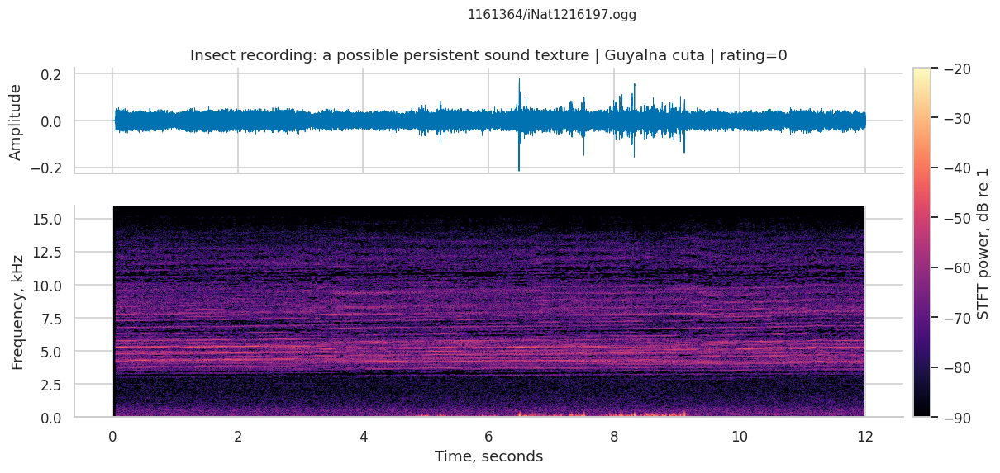

**Selection:** Insect recording: a possible persistent sound texture. **Group:** Insecta. **Clip-level labels:** `1161364`. Showing the first **12.0 s**; not all clip-level labels necessarily occur in this excerpt.

In [21]:
show_focal(example_texture, 'Insect recording: a possible persistent sound texture')

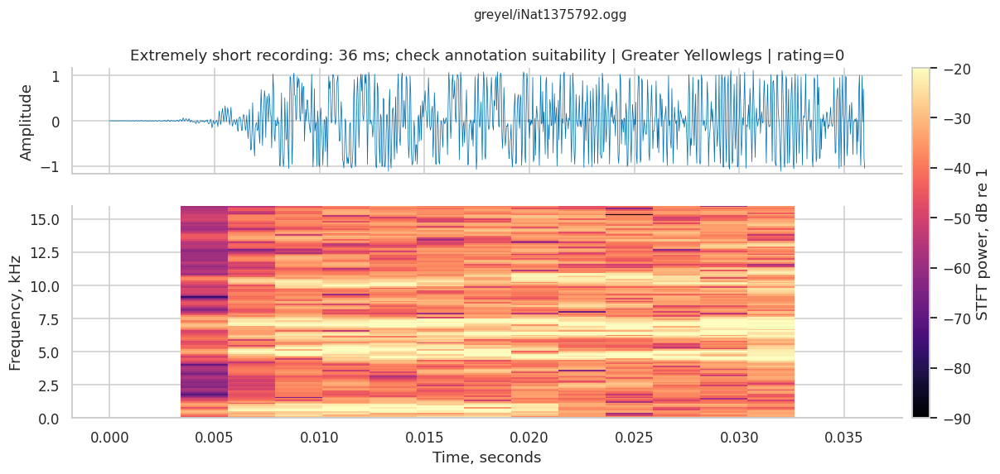

**Selection:** Extremely short recording: 36 ms; check annotation suitability. **Group:** Aves. **Clip-level labels:** `greyel`. Showing the first **0.0 s**; not all clip-level labels necessarily occur in this excerpt.

In [22]:
shortest = ok_headers.loc[ok_headers.source == 'focal'].nsmallest(1, 'duration_s').iloc[0]
show_focal(shortest.filename, f'Extremely short recording: {shortest.duration_s*1000:.0f} ms; check annotation suitability')

## 8. Soundscapes: spectrograms and species-presence timelines

These are diarization-like **species-presence visualizations**, not speaker diarization.
Each bar means that a species was annotated somewhere within a five-second window.
Two bars in the same window indicate co-presence; they **do not prove** that calls overlapped
at the same instant. Exact call onsets and offsets cannot be recovered from these labels.

Gray regions are unannotated, not necessarily quiet. Select three different files by annotation
complexity: relatively sparse, species-rich, and changing in label composition.
Waveforms and spectrograms help relate the annotations to the actual signal.

In [23]:
file_summary = windows.groupby('filename').agg(
    annotated_windows=('start_s', 'size'), max_species=('n_species', 'max'),
    mean_species=('n_species', 'mean'), richness=('labels', lambda rows: len({x for labels in rows for x in labels})),
)
def label_changes(group):
    records = group.sort_values('start_s')
    changes = 0
    previous = None
    for row in records.itertuples():
        current = set(row.labels)
        if previous is not None and np.isclose(previous[0], row.start_s):
            changes += len(current.symmetric_difference(previous[1]))
        previous = (row.end_s, current)
    return changes
file_summary['label_changes'] = pd.Series({name: label_changes(group) for name, group in windows.groupby('filename')})
eligible = file_summary.query('annotated_windows >= 8 and richness > 0')
sparse_file = eligible.sort_values(['max_species', 'mean_species', 'richness']).index[0]
dense_file = eligible.drop(index=[sparse_file]).sort_values(['max_species', 'richness'], ascending=False).index[0]
changing_file = eligible.drop(index=[sparse_file, dense_file]).sort_values(['label_changes', 'richness'], ascending=False).index[0]
display(file_summary.loc[[sparse_file, dense_file, changing_file]])

def species_name(label):
    if label not in tax.index:
        return label
    common_name = tax.loc[label, 'common_name']
    return f'{label} · {str(common_name)[:35]}'

def show_soundscape(filename, reason):
    audio, sample_rate = load_excerpt(ROOT / 'train_soundscapes' / filename, seconds=SOUNDSCAPE_SECONDS)
    intervals = windows.loc[windows.filename == filename].sort_values('start_s')
    labels = sorted({label for values in intervals.labels for label in values},
                    key=lambda label: (str(tax.loc[label, 'class_name']) if label in tax.index else '', label))
    duration = len(audio)/sample_rate
    f, t, db = spectrogram_db(audio, sample_rate)
    lane_height = max(3, 0.33 * len(labels))
    fig, axes = plt.subplots(3, 1, figsize=(16, 4.5 + lane_height), sharex=True,
                             gridspec_kw={'height_ratios': [1, 2.5, lane_height]})
    axes[0].plot(np.arange(len(audio))/sample_rate, audio, lw=0.4, color='#0072B2')
    peak = max(float(np.max(np.abs(audio))), 1e-5)
    axes[0].set(ylim=(-1.05*peak, 1.05*peak), ylabel='Amplitude', title=reason)
    shown_groups = sorted({str(tax.loc[label, 'class_name']) for label in labels if label in tax.index})
    axes[0].legend(handles=[Patch(facecolor=PALETTE.get(group, 'gray'), label=group) for group in shown_groups], loc='upper right', ncol=len(shown_groups), fontsize=8)
    image = axes[1].pcolormesh(t, f/1000, db, shading='auto', cmap='magma', vmin=-90, vmax=-20, rasterized=True)
    axes[1].set(ylabel='Frequency, kHz', ylim=(0, min(16, sample_rate/2000)))
    for y, label in enumerate(labels):
        segments = [(row.start_s, row.end_s - row.start_s) for row in intervals.itertuples() if label in row.labels]
        group = tax.loc[label, 'class_name'] if label in tax.index else 'Unknown'
        axes[2].broken_barh(segments, (y - 0.34, 0.68), facecolors=PALETTE.get(group, 'gray'), edgecolors='white', linewidth=0.5)
    annotated_starts = set(intervals.start_s)
    for start in range(0, int(np.ceil(duration)), WINDOW_SECONDS):
        if start not in annotated_starts:
            for ax in axes:
                ax.axvspan(start, min(start+WINDOW_SECONDS, duration), color='gray', alpha=0.28)
    for ax in axes:
        for boundary in range(0, int(duration)+1, WINDOW_SECONDS):
            ax.axvline(boundary, color='gray', lw=0.4, alpha=0.35)
    axes[2].set(yticks=range(len(labels)), yticklabels=[species_name(label) for label in labels],
                ylim=(-0.7, len(labels)-0.3), xlim=(0, duration), xlabel='Time, seconds',
                xticks=np.arange(0, duration+0.1, WINDOW_SECONDS))
    axes[2].set_title('5s annotation lanes: co-presence, not exact call boundaries', fontsize=11)
    fig.subplots_adjust(left=0.29, right=0.91, hspace=0.35)
    color_ax = fig.add_axes([0.925, 0.43, 0.012, 0.25])
    fig.colorbar(image, cax=color_ax, label='STFT power, dB re 1')
    fig.suptitle(filename, fontsize=11, y=0.99)
    plt.show()
    display(Markdown(f'**Annotated:** {len(intervals)} windows; **species in this file:** {len(labels)}; '
                     f'**maximum in one window:** {intervals.n_species.max()}. '
                     'Gray shading means unannotated. Continuous bars do not imply continuous vocalization.'))
    embedded_audio(audio, sample_rate)

,annotated_windows,max_species,mean_species,richness,label_changes
filename,,,,,
BC2026_Train_0012_S03_20220211_233000.ogg,12,2,1.083333,2,4
BC2026_Train_0063_S19_20241214_190000.ogg,12,10,7.750000,11,17
BC2026_Train_0024_S22_20211123_004500.ogg,12,5,3.750000,8,30


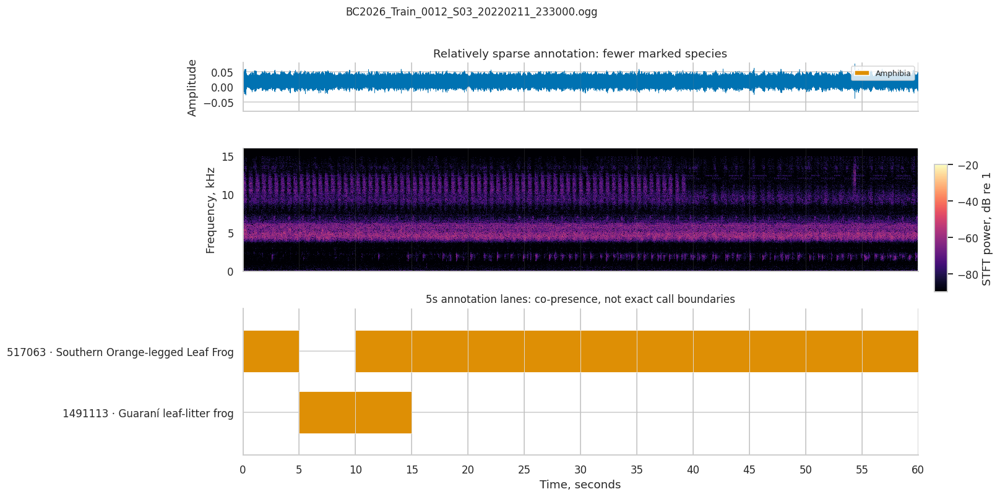

**Annotated:** 12 windows; **species in this file:** 2; **maximum in one window:** 2. Gray shading means unannotated. Continuous bars do not imply continuous vocalization.

In [24]:
show_soundscape(sparse_file, 'Relatively sparse annotation: fewer marked species')

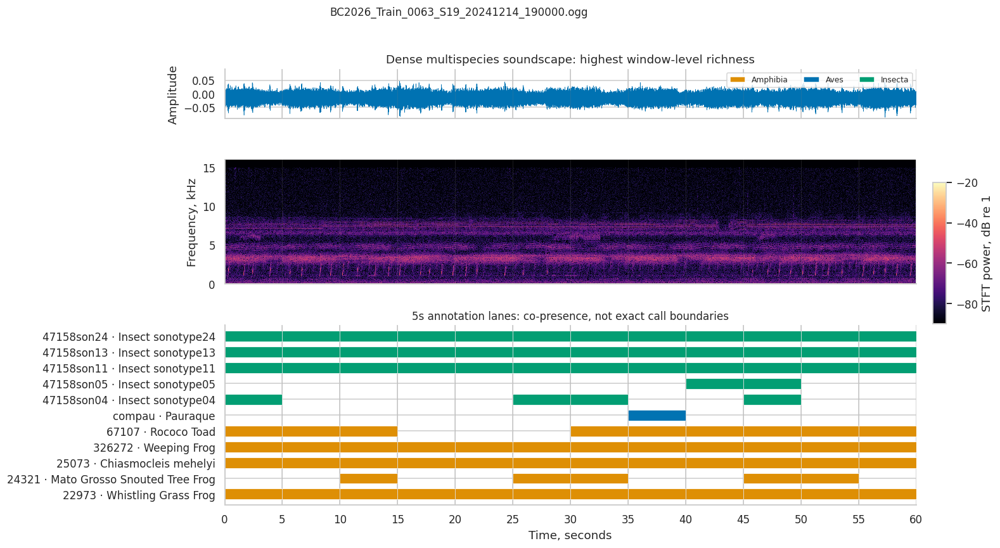

**Annotated:** 12 windows; **species in this file:** 11; **maximum in one window:** 10. Gray shading means unannotated. Continuous bars do not imply continuous vocalization.

In [25]:
show_soundscape(dense_file, 'Dense multispecies soundscape: highest window-level richness')

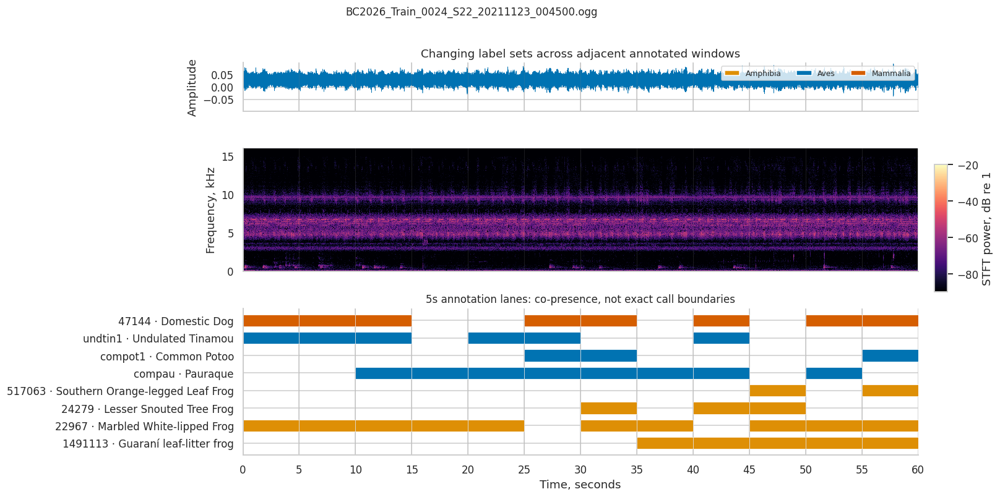

**Annotated:** 12 windows; **species in this file:** 8; **maximum in one window:** 5. Gray shading means unannotated. Continuous bars do not imply continuous vocalization.

In [26]:
show_soundscape(changing_file, 'Changing label sets across adjacent annotated windows')

## 8a. Five-second crop feasibility: a small listening study

Select **12 random focal recordings lasting 30–180 seconds** from the existing random header
sample. Decode each selected recording in full and draw **three deterministic random 5s crops**
per file. This bounded subset is exploratory, not a representative audit of all long recordings.
Keep the original audio examples above.

Trace 1s RMS at 250ms steps and 1–8 kHz STFT-band energy over time. The band is illustrative:
some species vocalize outside it. Random crops may overlap. Energy measures and crop/full-file
RMS differences cannot establish whether the labeled animal is audible. A crop more than 10 dB
below its file's RMS, or below −60 dBFS, is an **inspection flag**, not a false-label estimate or
an automatic rejection rule. Listen to all 36 crops in the expandable panels.

In [27]:
import html

N_CROP_FILES = 12
CROPS_PER_FILE = 3
crop_rng = np.random.default_rng(SEED)
crop_candidates = ok_headers.query('source == "focal" and 30 <= duration_s <= 180')
crop_selection = crop_candidates.sample(min(N_CROP_FILES, len(crop_candidates)), random_state=SEED)
crop_rows, crop_traces, crop_audio_panels, crop_errors = [], [], [], []
for record in tqdm(crop_selection.itertuples(index=False), total=len(crop_selection), desc='Full recordings for crop study', mininterval=2, ascii=True):
    try:
        audio, sample_rate = load_excerpt(record.path, seconds=record.duration_s+1)
        crop_size = int(WINDOW_SECONDS * sample_rate)
        if len(audio) < crop_size:
            raise ValueError('Decoded recording is shorter than five seconds.')
        file_rms_db = 20*np.log10(max(np.sqrt(np.mean(audio.astype(np.float64)**2)), 1e-12))
        starts = np.arange(0, len(audio)-sample_rate+1, max(1, int(0.25*sample_rate)))
        rms_trace = np.array([np.sqrt(np.mean(audio[start:start+sample_rate].astype(np.float64)**2)) for start in starts])
        frequencies, band_times, stft = signal.stft(audio, fs=sample_rate, nperseg=1024, noverlap=768,
                                                   boundary=None, padded=False)
        band_power = np.sum(np.abs(stft[(frequencies >= 1000) & (frequencies <= 8000)])**2, axis=0)
        band_db = 10*np.log10(np.maximum(band_power, 1e-12))
        sampled_starts = crop_rng.integers(0, len(audio)-crop_size+1, size=CROPS_PER_FILE)
        players = []
        for crop_number, start in enumerate(sampled_starts, start=1):
            crop = audio[start:start+crop_size]
            crop_rms_db = 20*np.log10(max(np.sqrt(np.mean(crop.astype(np.float64)**2)), 1e-12))
            relative_db = crop_rms_db-file_rms_db
            crop_rows.append({'filename': record.filename, 'crop': crop_number, 'start_s': start/sample_rate,
                              'end_s': (start+crop_size)/sample_rate, 'file_rms_db': file_rms_db,
                              'crop_rms_db': crop_rms_db, 'crop_minus_file_db': relative_db,
                              'relative_low_energy_flag': relative_db < -10, 'absolute_quiet_flag': crop_rms_db < -60})
            title = f'Crop {crop_number}: {start/sample_rate:.2f}–{(start+crop_size)/sample_rate:.2f}s | RMS {crop_rms_db:.1f} dBFS | vs file {relative_db:+.1f} dB'
            players.append(f'<p>{html.escape(title)}</p>' + audio_preview_html(crop, sample_rate))
        crop_traces.append({'filename': record.filename, 'duration_s': len(audio)/sample_rate,
                            'times': (starts+sample_rate/2)/sample_rate,
                            'rms_db': 20*np.log10(np.maximum(rms_trace, 1e-12)),
                            'band_times': band_times, 'band_db': band_db,
                            'crop_starts': sampled_starts/sample_rate})
        metadata = train.loc[train.filename == record.filename].iloc[0]
        summary = f'{record.filename} | {metadata.common_name} | {len(audio)/sample_rate:.1f}s | clip labels: {", ".join(metadata.labels)}'
        crop_audio_panels.append('<details><summary>'+html.escape(summary)+'</summary>'+''.join(players)+'</details>')
    except (OSError, RuntimeError, ValueError) as error:
        crop_errors.append({'filename': record.filename, 'error': str(error)})
crop_results = pd.DataFrame(crop_rows)
if crop_results.empty:
    raise ValueError('No valid crops; inspect the selected recordings and read errors.')
crop_study_summary = pd.Series({
    'Recordings selected': len(crop_selection), 'Recordings decoded': crop_results.filename.nunique(),
    'Random 5s crops': len(crop_results),
    'Crops >10dB below full-recording RMS': int(crop_results.relative_low_energy_flag.sum()),
    'Crops below -60 dBFS RMS': int(crop_results.absolute_quiet_flag.sum()),
    'Read/processing errors': len(crop_errors),
})
display(crop_study_summary.to_frame('count'))
display(crop_results.round(2))
if crop_errors:
    display(pd.DataFrame(crop_errors))


Full recordings for crop study: 100%|##########| 12/12 [00:03<00:00,  3.45it/s]


,count
Recordings selected,12
Recordings decoded,12
Random 5s crops,36
Crops >10dB below full-recording RMS,1
Crops below -60 dBFS RMS,0
Read/processing errors,0


,filename,crop,start_s,end_s,file_rms_db,crop_rms_db,crop_minus_file_db,relative_low_energy_flag,absolute_quiet_flag
0,sofspi1/XC705068.ogg,1,7.84,12.84,-29.83,-29.27,0.55,False,False
1,sofspi1/XC705068.ogg,2,68.00,73.00,-29.83,-30.47,-0.64,False,False
2,sofspi1/XC705068.ogg,3,57.51,62.51,-29.83,-28.94,0.89,False,False
3,sibtan2/XC146544.ogg,1,17.86,22.86,-30.96,-27.47,3.49,False,False
4,sibtan2/XC146544.ogg,2,17.62,22.62,-30.96,-27.56,3.40,False,False
5,sibtan2/XC146544.ogg,3,34.93,39.93,-30.96,-29.37,1.59,False,False
6,saffin/iNat592628.ogg,1,6.80,11.80,-40.32,-42.32,-2.00,False,False
7,saffin/iNat592628.ogg,2,55.16,60.16,-40.32,-44.42,-4.10,False,False
8,saffin/iNat592628.ogg,3,15.94,20.94,-40.32,-36.76,3.56,False,False
9,fabwre1/XC9621.ogg,1,3.33,8.33,-20.38,-13.26,7.12,False,False


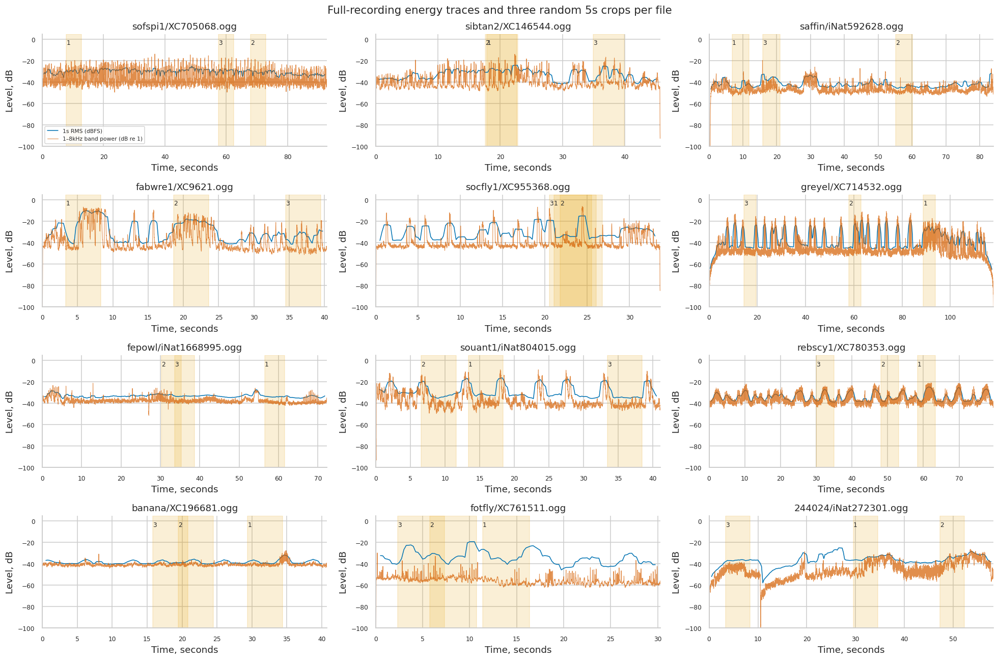

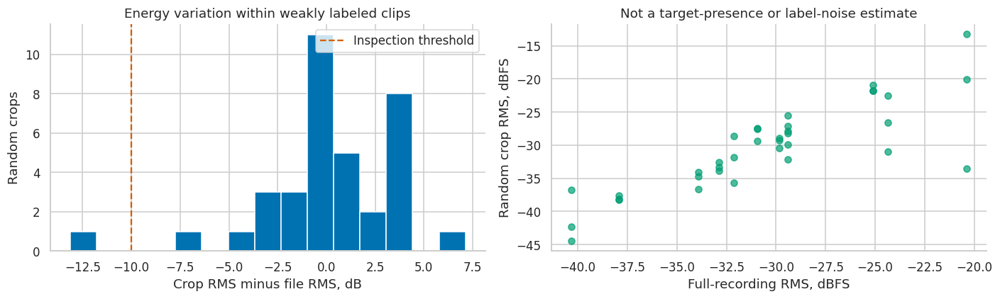

In [28]:
fig, axes = plt.subplots(4, 3, figsize=(18, 12), squeeze=False)
for ax, trace in zip(axes.flat, crop_traces):
    ax.plot(trace['times'], trace['rms_db'], color='#0072B2', lw=1, label='1s RMS (dBFS)')
    ax.plot(trace['band_times'], trace['band_db'], color='#D55E00', lw=0.7, alpha=0.7, label='1–8kHz band power (dB re 1)')
    for crop_number, start in enumerate(trace['crop_starts'], start=1):
        ax.axvspan(start, start+WINDOW_SECONDS, color='#E69F00', alpha=0.16)
        ax.text(start, 0.95, str(crop_number), transform=ax.get_xaxis_transform(), va='top', fontsize=8)
    ax.set(title=trace['filename'], xlabel='Time, seconds', ylabel='Level, dB', xlim=(0, trace['duration_s']), ylim=(-100, 5))
    ax.tick_params(labelsize=8)
for ax in axes.flat[len(crop_traces):]:
    ax.set_visible(False)
axes.flat[0].legend(fontsize=7, loc='lower left')
fig.suptitle('Full-recording energy traces and three random 5s crops per file', fontsize=14)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(crop_results.crop_minus_file_db, bins=15, color='#0072B2')
axes[0].axvline(-10, color='#D55E00', ls='--', label='Inspection threshold')
axes[0].set(xlabel='Crop RMS minus file RMS, dB', ylabel='Random crops', title='Energy variation within weakly labeled clips')
axes[0].legend()
axes[1].scatter(crop_results.file_rms_db, crop_results.crop_rms_db, color='#009E73', alpha=0.7)
axes[1].set(xlabel='Full-recording RMS, dBFS', ylabel='Random crop RMS, dBFS', title='Not a target-presence or label-noise estimate')
fig.tight_layout()
plt.show()

In [29]:
display(Markdown('Expand each recording to listen to its three sampled crops. Clip-level labels apply to the source recording, not necessarily to every crop. Playback is not amplified.'))
for panel in crop_audio_panels:
    display(HTML(panel))

Expand each recording to listen to its three sampled crops. Clip-level labels apply to the source recording, not necessarily to every crop. Playback is not amplified.

## 8b. Baseline preprocessing preview: one 5s Log-Mel input

Inspect a concrete frontend candidate without implementing or training a model: 32 kHz input,
1024-sample FFT, 320-sample hop (10 ms), 128 Mel bands, and 50–14,000 Hz limits. This is a
preview, not a final baseline decision. `center=False` avoids implicit centering padding.
The Mel-power reference differs from the normalized STFT plots above, so do not compare their
color values directly. No fitted dataset normalization or augmentation is applied.

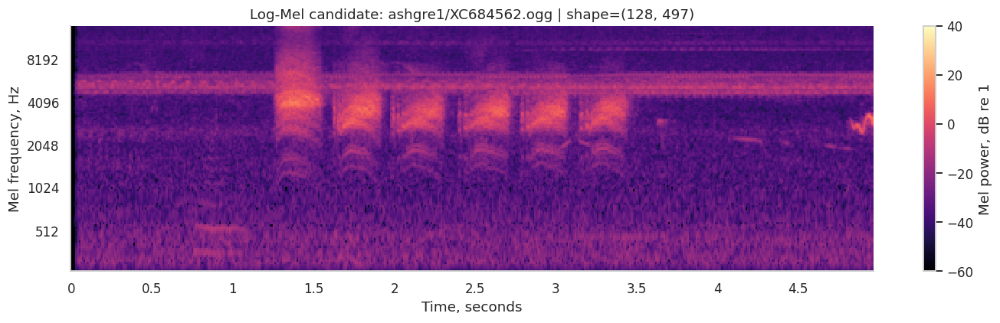

{'waveform_samples': 160000,
 'sample_rate': 32000,
 'logmel_shape': (128, 497),
 'dtype': 'float32',
 'all_finite': True}

In [30]:
import librosa
import librosa.display

mel_audio, mel_sample_rate = load_excerpt(ROOT / 'train_audio' / example_high, seconds=WINDOW_SECONDS)
mel_power = librosa.feature.melspectrogram(
    y=mel_audio, sr=mel_sample_rate, n_fft=1024, hop_length=320, n_mels=128,
    fmin=50, fmax=min(14000, mel_sample_rate/2), power=2, center=False,
)
mel_db = librosa.power_to_db(mel_power, ref=1.0, top_db=80)
fig, ax = plt.subplots(figsize=(13, 4))
image = librosa.display.specshow(mel_db, sr=mel_sample_rate, hop_length=320, x_axis='time',
                                y_axis='mel', fmin=50, fmax=min(14000, mel_sample_rate/2),
                                vmin=-60, vmax=40, cmap='magma', ax=ax)
ax.set(title=f'Log-Mel candidate: {example_high} | shape={mel_db.shape}', xlabel='Time, seconds', ylabel='Mel frequency, Hz')
fig.colorbar(image, ax=ax, label='Mel power, dB re 1')
fig.tight_layout()
plt.show()
display({'waveform_samples': len(mel_audio), 'sample_rate': mel_sample_rate,
         'logmel_shape': mel_db.shape, 'dtype': str(mel_db.dtype),
         'all_finite': bool(np.isfinite(mel_db).all())})

## 8c. External resources: candidates, not downloaded inputs

Inventory checked on **2026-10-24** using primary project/data pages. No external audio or model
weights are downloaded here. Target-class mapping, duplicate overlap, and CPU/offline performance
remain unverified; a published model is not automatically a suitable competition input.

| Resource | Potential experiment | Availability / license evidence | Checks before use |
|---|---|---|---|
| [Google Perch](https://github.com/google-research/perch) / [Perch-Hoplite](https://github.com/google-research/perch-hoplite) | Frozen embeddings, then possibly a distillation teacher | Official code and released model links are public. The original Perch repository directs practical inference users to Hoplite; inspect the selected model card separately from the code license. | Pin the artifact/version; check input format, species coverage, CPU timing, weight license, and possible pretraining overlap. |
| [BirdNET-Analyzer](https://github.com/birdnet-team/BirdNET-Analyzer) | Alternative embeddings or teacher | Official project exposes embeddings tooling; code is MIT and model terms are CC BY-NC-SA 4.0, subject to each artifact's terms. | Verify mapping to bird and non-bird targets, model version, required sample rate, and end-to-end offline CPU feasibility. |
| [Xeno-canto](https://xeno-canto.org/) | Only targeted additional focal supervision if an actual gap remains | Already a source of the supplied training audio. Its terms page could not be inspected by the research tool; do not infer reuse permission from public availability. | Check each recording's current license/source ID and existing training URLs; avoid redundant scraping. The [competition data description](https://www.kaggle.com/competitions/birdclef-2026/data) discourages burdening the source portals for redundant audio. |
| [iNaturalist](https://www.inaturalist.org/pages/terms) | Investigate coverage of underrepresented taxa | Already a training source. Contributors retain rights and content licensing can vary; inspect the specific sound's terms. | Match taxon IDs, recording IDs and licenses; audit duplicates and annotation reliability before any download. |
| [FSD50K](https://zenodo.org/records/4060432) | General environmental-audio pretraining or background augmentation | Public multilabel sound-event dataset, not a BirdCLEF species taxonomy. Dataset-level CC BY coexists with per-clip licenses. | Use an appropriate subset and check every clip's license and overlap; broad event labels are not positive BirdCLEF species labels. |

Prefer a small, reproducible encoder comparison before expanding the data inventory. No claim
is made that an external resource fixes any of the measured supervision gaps.

## 9. Considerations before modeling

The following findings come from this execution. Distinguish measured facts from risks that
still require investigation. No label does not mean no sound; high RMS does not mean noise;
co-presence does not mean exact acoustic overlap. This EDA neither trains a model nor selects
a final validation split.

In [32]:
multispecies_fraction = windows.n_species.ge(2).mean()
no_focal = int((any_clip_counts == 0).sum())
sc_only = int(((any_clip_counts == 0) & (sc_counts > 0)).sum())
dominant_site = sc_inventory.loc[sc_inventory.labeled, 'site'].value_counts(normalize=True)
top_author_share = train.loc[train.author.notna() & train.author.ne('Unknown'), 'author'].value_counts().head(10).sum()/len(train)
short_fraction = (focal_durations < 5).mean()
long_fraction = (focal_durations > 60).mean()
site_note = f'{dominant_site.index[0]}: {dominant_site.iloc[0]:.1%}' if len(dominant_site) else 'unknown'
display(Markdown(f'''
### Measured findings

- **{len(train):,}** focal recordings; **{len(classes)}** target classes; **{len(sc_paths):,}** train soundscapes.
- **{len(sc_raw)-len(sc)}** exact duplicate soundscape annotation rows were removed from the working EDA table only.
- After aggregation: **{len(windows)}** unique valid windows in **{windows.filename.nunique()}** labeled files.
- **{int((~grid.annotated).sum())}** five-second slots within labeled files have no annotations.
- In **{multispecies_fraction:.1%}** of annotated windows, at least two species are marked present; the maximum is **{windows.n_species.max()}**.
- **{no_focal}** classes have no focal labels; of these, **{sc_only}** have positive soundscape windows.
- Shortest focal recording in the sample: **{focal_durations.min()*1000:.0f} ms**. Padding does not add useful signal; these recordings need separate inspection.
- The top 10 classes account for **{ranked.head(10).sum()/len(train):.1%}** of focal recordings; the top 10 known contributors account for **{top_author_share:.1%}**.
- **{len(identical_pairs)}** class pairs have identical window-level annotations (at least 5 positive windows).
- Most represented site in the labeled subset: **{site_note}**.
- In the random sample of **{len(focal_durations)}** readable focal headers: **{short_fraction:.1%}** of recordings are shorter than 5s,
  **{long_fraction:.1%}** are longer than one minute. Header read errors: **{len(header_failures)}** out of **{len(headers)}** checked.

### Implications and open questions

1. **Different annotation granularity.** Focal secondary labels do not localize vocalizations. A random 5s crop may not contain an annotated species.
2. **Rare and soundscape-only classes.** Focal-only training may be insufficient; check supervision coverage per class.
3. **Validation leakage.** Keep windows from the same recording together. Contributors, source URLs, and sites are additional candidate grouping keys.
4. **Small, biased labeled subset.** File-level and site-level validation test different scenarios; one CV score may be insufficient.
5. **Signal quality.** Inspect padding/cropping, multichannel downmixing, quiet recordings, and persistent textures on a larger audio sample.
6. **Not yet verified.** Full-file decodability across the dataset, byte-identical and acoustic duplicates, annotation accuracy, and true SNR.
'''))


### Measured findings

- **35,549** focal recordings; **234** target classes; **10,658** train soundscapes.
- **739** exact duplicate soundscape annotation rows were removed from the working EDA table only.
- After aggregation: **739** unique valid windows in **66** labeled files.
- **53** five-second slots within labeled files have no annotations.
- In **89.4%** of annotated windows, at least two species are marked present; the maximum is **10**.
- **28** classes have no focal labels; of these, **28** have positive soundscape windows.
- Shortest focal recording in the sample: **36 ms**. Padding does not add useful signal; these recordings need separate inspection.
- The top 10 classes account for **13.9%** of focal recordings; the top 10 known contributors account for **24.8%**.
- **3** class pairs have identical window-level annotations (at least 5 positive windows).
- Most represented site in the labeled subset: **S22: 60.6%**.
- In the random sample of **800** readable focal headers: **9.6%** of recordings are shorter than 5s,
  **12.2%** are longer than one minute. Header read errors: **0** out of **1064** checked.

### Implications and open questions

1. **Different annotation granularity.** Focal secondary labels do not localize vocalizations. A random 5s crop may not contain an annotated species.
2. **Rare and soundscape-only classes.** Focal-only training may be insufficient; check supervision coverage per class.
3. **Validation leakage.** Keep windows from the same recording together. Contributors, source URLs, and sites are additional candidate grouping keys.
4. **Small, biased labeled subset.** File-level and site-level validation test different scenarios; one CV score may be insufficient.
5. **Signal quality.** Inspect padding/cropping, multichannel downmixing, quiet recordings, and persistent textures on a larger audio sample.
6. **Not yet verified.** Full-file decodability across the dataset, byte-identical and acoustic duplicates, annotation accuracy, and true SNR.


## 10. EDA -> modeling decisions

These are proposed first experiments, not measured model improvements. Preserve a record of
the exact validation groups and scoring classes before comparing models. The table below is
computed from this EDA run rather than assuming every target is represented in every fold.

In [34]:
decision_rows = [
    (f'{int((any_clip_counts == 0).sum())} classes lack focal labels',
     'Use both focal and labeled soundscape supervision; track classes missing from each training fold.',
     'Weak clip labels and interval labels need different sample-building rules.'),
    (f'{len(windows)} annotated windows from {windows.filename.nunique()} files; {len(observed_classes)} observed classes',
     'Start with a frozen pretrained encoder and a small head before broader fine-tuning.',
     'Report globally pooled grouped OOF AUC and per-class support, not just a mean of fold AUCs.'),
    (f'{int((~globally_observed).sum())} classes have no positive annotated soundscape windows',
     'Track evaluation coverage separately from the full 234-class prediction contract.',
     'Local CV cannot directly assess performance on these absent classes.'),
    (f'{int(class_coverage.positive_sites.eq(1).sum())} observed classes occur at only one positive site',
     'Compare file-level and site-level grouped validation; retain site-held-out stress tests.',
     'A site split measures a harder and different generalization scenario, often with unseen labels.'),
    (f'{int(fold_report.val_no_negative_classes.gt(0).sum())} diagnostic folds contain classes without negatives',
     'Fail explicitly on undefined per-fold AUC; use a valid pooled OOF evaluation or revise the split.',
     'Do not silently exclude all-positive validation classes and call it the competition metric.'),
    (f'{len(crop_results)} random crops inspected from {crop_results.filename.nunique()} long recordings',
     'Compare random cropping with a bounded energy-aware crop policy in a later controlled experiment.',
     'Energy flags are not target-presence labels; no observed false-label rate was measured.'),
    (f'{(focal_durations < WINDOW_SECONDS).mean():.1%} of sampled focal files are shorter than 5s',
     'Make padding and very-short-recording handling explicit; log any exclusions.',
     'Do not delete files automatically from this sampled EDA or assume padding creates information.'),
    (f'{windows.n_species.ge(2).mean():.1%} of annotated windows contain multiple species',
     'Use multilabel targets with BCE/logits for training and sigmoid probabilities at inference.',
     'Compare architectures using the same window labels and validation grouping.'),
    ('Source-dependent ratings/secondary labels and differing geographic coverage',
     'Compare source-aware sampling and pretrained representations before adding location priors.',
     'Missing ratings are not low-quality scores; the recorder envelope is not exact test geography.'),
]
modeling_decisions = pd.DataFrame(decision_rows, columns=['Measured finding', 'Proposed first experiment / decision', 'Guardrail'])
display(modeling_decisions.style.set_properties(**{'text-align': 'left', 'white-space': 'normal'}).hide(axis='index'))
display(Markdown('**Next baseline boundary:** independently prepared audio windows and targets -> shared encoder inputs -> multilabel head. Keep dataset construction, frontend parameters, class order, and split membership explicit. No model has been trained or selected by this notebook.'))

Measured finding,Proposed first experiment / decision,Guardrail
28 classes lack focal labels,Use both focal and labeled soundscape supervision; track classes missing from each training fold.,Weak clip labels and interval labels need different sample-building rules.
739 annotated windows from 66 files; 75 observed classes,Start with a frozen pretrained encoder and a small head before broader fine-tuning.,"Report globally pooled grouped OOF AUC and per-class support, not just a mean of fold AUCs."
159 classes have no positive annotated soundscape windows,Track evaluation coverage separately from the full 234-class prediction contract.,Local CV cannot directly assess performance on these absent classes.
50 observed classes occur at only one positive site,Compare file-level and site-level grouped validation; retain site-held-out stress tests.,"A site split measures a harder and different generalization scenario, often with unseen labels."
2 diagnostic folds contain classes without negatives,Fail explicitly on undefined per-fold AUC; use a valid pooled OOF evaluation or revise the split.,Do not silently exclude all-positive validation classes and call it the competition metric.
36 random crops inspected from 12 long recordings,Compare random cropping with a bounded energy-aware crop policy in a later controlled experiment.,Energy flags are not target-presence labels; no observed false-label rate was measured.
9.6% of sampled focal files are shorter than 5s,Make padding and very-short-recording handling explicit; log any exclusions.,Do not delete files automatically from this sampled EDA or assume padding creates information.
89.4% of annotated windows contain multiple species,Use multilabel targets with BCE/logits for training and sigmoid probabilities at inference.,Compare architectures using the same window labels and validation grouping.
Source-dependent ratings/secondary labels and differing geographic coverage,Compare source-aware sampling and pretrained representations before adding location priors.,Missing ratings are not low-quality scores; the recorder envelope is not exact test geography.


**Next baseline boundary:** independently prepared audio windows and targets -> shared encoder inputs -> multilabel head. Keep dataset construction, frontend parameters, class order, and split membership explicit. No model has been trained or selected by this notebook.